# Paper 2 — revision analyses (reviewer comments M1–M11)
**Kaggle settings:** GPU T4 ×2 · Internet ON · Inputs: `CICIDS2017` (mdalamintalukder) and `CIC-DoS2017` (dhoogla).

**Run:** Save Version → *Save & Run All (Commit)*; close the browser (~3.5–4 h).

**Result:** Versions → latest → Output → `paper2_revision_outputs.zip`, plus the Logs.

Cells R1–R9 are fail-safe: a failing cell prints `!! Rx FAILED` and the run continues.

### Cell 1 — Setup, imports and device (Section 1)

In [1]:
"""
FGSAN-RI : re-timing-invariant slow-HTTP detection
COMPLETE notebook, split into one cell per section. Run cells in order.

 1 setup + device          10 degeneracy audit
 2 metrics/thresholds      11 model
 3 training loop           12 augmentation
 4 results ledger          13 feature sets + splits
 5 data download           14 train + evaluate
 6 data load               15 results tables
 7 cache                   16 displacement tolerance
 8 invariant transform     17 save + summary
 9 invariance proof

Sections 13-16 skip cleanly if CICIDS2017 is absent.
"""

import os
import sys
import math
import random
import copy
import json
import time
import gc
import glob
import shutil
import subprocess
import pickle
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import f1_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_recall_curve
from sklearn.ensemble import RandomForestClassifier

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False


# ===================================================
# SECTION 1 : setup and device
# ===================================================

NB_VERSION = "fgsan-ri-2.0"
SPLIT_SEED = 42
SEEDS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
RUN_SEEDS = SEEDS[:5]

N_GPU = torch.cuda.device_count()
DEVICES = ["cuda:{}".format(i) for i in range(N_GPU)] or ["cpu"]
DEVICE = DEVICES[0]

ON_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working" if ON_KAGGLE else "/content"
PROJ = os.path.join(WORK, "fgsan_ri")
INPUT_DIR = "/kaggle/input" if ON_KAGGLE else "/content/input"
RAW2018 = os.path.join(WORK, "raw2018")
for s in ("", "checkpoints", "logs", "figures", "tables"):
    os.makedirs(os.path.join(PROJ, s), exist_ok=True)
os.makedirs(RAW2018, exist_ok=True)
RESULTS_CSV = os.path.join(PROJ, "results.csv")
LEDGER = os.path.join(PROJ, "Ledger.md")
CKPT = os.path.join(PROJ, "checkpoints")


def require(*names):
    miss = [n for n in names if n not in globals()]
    if miss:
        raise RuntimeError("missing: {}".format(miss))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def log_ledger(tag, lines):
    txt = ""
    if os.path.exists(LEDGER):
        txt = open(LEDGER, encoding="utf-8").read()
    if tag in txt:
        return False
    with open(LEDGER, "a", encoding="utf-8") as f:
        f.write("\n## {} ({})\n".format(
            tag, datetime.now(timezone.utc).isoformat()))
        for ln in lines:
            f.write("- {}\n".format(ln))
    return True


print("=" * 62)
print("SECTION 1 : setup", NB_VERSION)
print("=" * 62)
print("  torch      :", torch.__version__)
print("  gpu count  :", N_GPU)
for _i in range(N_GPU):
    _p = torch.cuda.get_device_properties(_i)
    print("    cuda:{}  {}  {:.0f} GB".format(
        _i, _p.name, _p.total_memory / 1e9))
print("  train dev  :", DEVICE)
if N_GPU > 1:
    print("  NOTE: FGSAN is ~11k params. DataParallel would")
    print("  be SLOWER than one GPU. Pinned to cuda:0.")
    print("  Trees use all CPU cores (n_jobs=-1).")
if N_GPU == 0:
    print("  NO GPU - enable the accelerator in the sidebar.")
print("  proj       :", PROJ)

set_seed(7)
_a = nn.Linear(4, 4).weight.clone()
set_seed(7)
_b = nn.Linear(4, 4).weight.clone()
set_seed(8)
_c = nn.Linear(4, 4).weight.clone()
assert torch.equal(_a, _b) and not torch.equal(_a, _c)
print("  seeding    : deterministic OK")

SECTION 1 : setup fgsan-ri-2.0
  torch      : 2.10.0+cu128
  gpu count  : 2
    cuda:0  Tesla T4  16 GB
    cuda:1  Tesla T4  16 GB
  train dev  : cuda:0
  NOTE: FGSAN is ~11k params. DataParallel would
  be SLOWER than one GPU. Pinned to cuda:0.
  Trees use all CPU cores (n_jobs=-1).
  proj       : /kaggle/working/fgsan_ri
  seeding    : deterministic OK


### Cell 2 — Section 2: metrics and thresholds

In [2]:
# ===================================================
# SECTION 2 : metrics and thresholds
# ===================================================

NAN = float("nan")
_WARNED = set()


def compute_metrics(y_true, y_score, threshold=0.5,
                    eval_type="full"):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    if len(y_true) != len(y_score):
        raise ValueError("length mismatch")
    if len(y_true) == 0:
        raise ValueError("empty eval set")
    y_pred = (y_score >= threshold).astype(int)
    if eval_type == "benign_only":
        if (y_true == 1).any():
            raise ValueError("positives in benign_only")
        return {"eval_type": "benign_only",
                "threshold": float(threshold),
                "f1": NAN, "auc_pr": NAN, "auc_roc": NAN,
                "fnr": NAN,
                "benign_fpr": float((y_pred == 1).mean()),
                "n_benign": len(y_true), "n_attack": 0,
                "tp": 0, "tn": int((y_pred == 0).sum()),
                "fp": int((y_pred == 1).sum()), "fn": 0}
    if eval_type != "full":
        raise ValueError("bad eval_type")
    if not (y_true == 1).any():
        raise ValueError("'full' needs attacks")
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]).ravel()
    hb = bool((y_true == 0).any())
    return {"eval_type": "full",
            "threshold": float(threshold),
            "f1": float(f1_score(y_true, y_pred,
                                 zero_division=0)),
            "auc_pr": float(average_precision_score(
                y_true, y_score)),
            "auc_roc": float(roc_auc_score(y_true, y_score))
            if hb else NAN,
            "fnr": float(fn / (fn + tp)) if (fn + tp) else NAN,
            "benign_fpr": float(fp / (fp + tn))
            if (fp + tn) else NAN,
            "n_benign": int((y_true == 0).sum()),
            "n_attack": int((y_true == 1).sum()),
            "tp": int(tp), "tn": int(tn),
            "fp": int(fp), "fn": int(fn)}


def calibrate_threshold_at_fpr(y_true, y_score,
                               target_fpr=0.001, warn=True):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    benign = np.sort(y_score[y_true == 0])
    n = len(benign)
    if n == 0:
        raise ValueError("no benign samples")
    k = int(np.floor(n * target_fpr))
    if k < 10 and warn and (target_fpr, n) not in _WARNED:
        _WARNED.add((target_fpr, n))
        print("    WARN fpr={:g} on {} benign allows {} FP"
              .format(target_fpr, n, k))
    if k == 0:
        return float(np.nextafter(benign[-1], np.inf))
    t = float(benign[n - k])
    above = n - np.searchsorted(benign, t, side="left")
    if above > k:
        gt = benign[benign > t]
        t = float(gt[0]) if len(gt) else float(
            np.nextafter(benign[-1], np.inf))
    return t


def oracle_threshold(y_true, y_score):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    if not (y_true == 1).any():
        raise ValueError("oracle needs attacks")
    p, r, thr = precision_recall_curve(y_true, y_score)
    if len(thr) == 0:
        return 0.5
    d = p + r
    f1 = np.divide(2 * p * r, d, out=np.zeros_like(p),
                   where=d > 0)
    return float(thr[min(int(np.argmax(f1)), len(thr) - 1)])


def resolve_threshold(mode, src_val_y=None, src_val_score=None,
                      tgt_y=None, tgt_score=None,
                      target_fpr=0.001):
    if mode == "fixed":
        return 0.5
    if mode == "src_cal":
        return calibrate_threshold_at_fpr(
            src_val_y, src_val_score, target_fpr)
    if mode == "matched_fpr":
        return calibrate_threshold_at_fpr(
            tgt_y, tgt_score, target_fpr, warn=False)
    if mode == "oracle":
        return oracle_threshold(tgt_y, tgt_score)
    raise ValueError("bad mode " + str(mode))


THRESHOLD_MODES = ("fixed", "src_cal", "matched_fpr", "oracle")


def bootstrap_ci(y_true, y_score, threshold, stat="fnr",
                 n_boot=2000, seed=SPLIT_SEED):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    rng = np.random.default_rng(seed)
    atk = np.flatnonzero(y_true == 1)
    ben = np.flatnonzero(y_true == 0)
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([
            rng.choice(atk, len(atk), replace=True),
            rng.choice(ben, len(ben), replace=True)])
        try:
            v = compute_metrics(y_true[idx], y_score[idx],
                                threshold, "full")[stat]
        except ValueError:
            continue
        if not (isinstance(v, float) and math.isnan(v)):
            vals.append(v)
    if not vals:
        return NAN, NAN, NAN
    v = np.asarray(vals)
    return (float(v.mean()),
            float(np.percentile(v, 2.5)),
            float(np.percentile(v, 97.5)))


print("")
print("=" * 62)
print("SECTION 2 : metrics")
print("=" * 62)
_r = np.random.default_rng(SPLIT_SEED)
_y = (_r.random(4000) < 0.2).astype(int)
_s = np.clip(_r.normal(np.where(_y == 1, .75, .25), .15,
                       4000), 0, 1)
for _m in THRESHOLD_MODES:
    _t = resolve_threshold(_m, src_val_y=_y, src_val_score=_s,
                           tgt_y=_y, tgt_score=_s,
                           target_fpr=0.01)
    _mm = compute_metrics(_y, _s, _t, "full")
    print("  {:<12} thr={:.4f} fnr={:.4f} fpr={:.5f}".format(
        _m, _t, _mm["fnr"], _mm["benign_fpr"]))
_bm, _lo, _hi = bootstrap_ci(_y, _s, 0.5, "fnr", 400)
print("  bootstrap fnr {:.4f} CI [{:.4f}, {:.4f}]".format(
    _bm, _lo, _hi))
assert _lo < _bm < _hi


SECTION 2 : metrics
  fixed        thr=0.5000 fnr=0.0473 fpr=0.05197
  src_cal      thr=0.6076 fnr=0.1891 fpr=0.00976
  matched_fpr  thr=0.6076 fnr=0.1891 fpr=0.00976
  oracle       thr=0.5680 fnr=0.1091 fpr=0.01575
  bootstrap fnr 0.0475 CI [0.0327, 0.0630]


### Cell 3 — Section 3: training loop

In [3]:
# ===================================================
# SECTION 3 : training loop
# ===================================================

class TrainConfig:
    batch_size = 256
    epochs = 30
    lr = 1e-3
    weight_decay = 1e-5
    emb_dim = 32
    n_heads = 4
    dropout = 0.3
    focal_gamma = 2.0
    focal_alpha = 0.25
    select_metric = "auc_pr"
    patience = None
    min_epochs = 5
    aug_prob = 0.5


class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.25):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction="none")
        pt = torch.exp(-ce)
        return (self.alpha * (1 - pt) ** self.gamma * ce).mean()


@torch.no_grad()
def predict_probs(model, X, batch_size=8192):
    model.eval()
    dev = next(model.parameters()).device
    out = np.empty(len(X), dtype=np.float32)
    for s in range(0, len(X), batch_size):
        e = min(s + batch_size, len(X))
        xb = torch.as_tensor(np.asarray(X[s:e]),
                             dtype=torch.float32, device=dev)
        out[s:e] = torch.softmax(
            model(xb), -1)[:, 1].cpu().numpy()
    return out


def train_model(model, X_tr, y_tr, X_val, y_val, cfg,
                augment_fn=None, use_focal=True,
                device=None, verbose=True):
    dev = device or DEVICE
    if not (np.asarray(y_val) == 1).any():
        raise ValueError("val has no attacks")
    model = model.to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr,
                           weight_decay=cfg.weight_decay)
    crit = (FocalLoss(cfg.focal_gamma, cfg.focal_alpha)
            if use_focal else nn.CrossEntropyLoss())
    Xt = torch.as_tensor(X_tr, dtype=torch.float32, device=dev)
    yt = torch.as_tensor(y_tr, dtype=torch.long, device=dev)
    n = len(y_tr)
    nb = math.ceil(n / cfg.batch_size)
    gen = torch.Generator(device=dev).manual_seed(
        int(torch.randint(0, 2 ** 31, (1,)).item()))
    best = -np.inf
    best_ep = -1
    stale = 0
    best_state = copy.deepcopy(model.state_dict())
    hist = []
    for ep in range(1, cfg.epochs + 1):
        model.train()
        perm = torch.randperm(n, device=dev)
        tot = 0.0
        for b in range(nb):
            bi = perm[b * cfg.batch_size:(b + 1) * cfg.batch_size]
            xb = Xt[bi]
            yb = yt[bi]
            if augment_fn is not None and cfg.aug_prob > 0:
                k = int(len(bi) * cfg.aug_prob)
                if k > 0:
                    xb = torch.cat(
                        [augment_fn(xb[:k], yb[:k], gen),
                         xb[k:]], 0)
                    model.train()
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
            tot += loss.item()
        vm = compute_metrics(
            y_val, predict_probs(model, X_val), 0.5, "full")
        sc = vm[cfg.select_metric]
        hist.append({"epoch": ep, "loss": tot / nb,
                     "val_auc_pr": vm["auc_pr"],
                     "select_score": sc})
        if sc > best:
            best = sc
            best_ep = ep
            stale = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
        if verbose and (ep % 10 == 0 or ep == 1):
            print("    ep {:3d}/{} loss={:.4f} "
                  "auc_pr={:.4f} best={:.4f}@{}".format(
                      ep, cfg.epochs, tot / nb,
                      vm["auc_pr"], best, best_ep))
        if cfg.patience and ep >= cfg.min_epochs:
            if stale >= cfg.patience:
                break
    model.load_state_dict(best_state)
    return model, {"history": hist, "best_epoch": best_ep,
                   "best_score": float(best),
                   "epochs_run": len(hist),
                   "augmented": augment_fn is not None}


print("")
print("=" * 62)
print("SECTION 3 : training loop")
print("=" * 62)


class _Tiny(nn.Module):
    def __init__(self, d=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, 32), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(32, 2))

    def forward(self, x):
        return self.net(x)


_rg = np.random.default_rng(SPLIT_SEED)
_Xs = _rg.normal(size=(3000, 10)).astype(np.float32)
_ys = ((_Xs[:, 0] + .8 * _Xs[:, 1]) > .7).astype(np.int64)
_cfg = TrainConfig()
_cfg.epochs = 10
set_seed(1)
_m1, _i1 = train_model(_Tiny(), _Xs[:2000], _ys[:2000],
                       _Xs[2000:2500], _ys[2000:2500],
                       _cfg, verbose=False)
_v = compute_metrics(_ys[2000:2500],
                     predict_probs(_m1, _Xs[2000:2500]),
                     0.5, "full")[_cfg.select_metric]
assert abs(_i1["best_score"] - _v) < 1e-5
set_seed(1)
_m2, _i2 = train_model(_Tiny(), _Xs[:2000], _ys[:2000],
                       _Xs[2000:2500], _ys[2000:2500],
                       _cfg, verbose=False)
assert abs(_i1["best_score"] - _i2["best_score"]) < 1e-6
print("  checkpoint restore + reproducibility: OK")
del _m1, _m2
gc.collect()


SECTION 3 : training loop
  checkpoint restore + reproducibility: OK


30

### Cell 4 — Section 4: results ledger

In [4]:
# ===================================================
# SECTION 4 : results ledger
# ===================================================

RESULTS_COLUMNS = [
    "run_id", "timestamp", "nb_version",
    "model", "feature_set", "augmentation", "seed",
    "train_dataset", "eval_dataset", "attack_family",
    "stratum", "threshold_mode", "threshold_value",
    "eval_type", "eval_prevalence", "target_fpr",
    "f1", "auc_pr", "auc_roc", "fnr", "benign_fpr",
    "precision", "recall", "mcc",
    "n_benign", "n_attack", "tp", "tn", "fp", "fn",
    "fnr_boot_mean", "fnr_boot_lo", "fnr_boot_hi",
    "aucpr_boot_mean", "aucpr_boot_lo", "aucpr_boot_hi",
    "displacement_factor", "retiming_factor",
    "detection_rate", "best_epoch", "epochs_run", "notes",
]
RUN_KEY = ["model", "feature_set", "augmentation", "seed",
           "train_dataset", "eval_dataset", "attack_family",
           "stratum", "threshold_mode", "eval_type",
           "displacement_factor", "retiming_factor"]


def init_results(path=RESULTS_CSV):
    if not os.path.exists(path):
        pd.DataFrame(columns=RESULTS_COLUMNS).to_csv(
            path, index=False)
    return path


def load_results(path=RESULTS_CSV):
    init_results(path)
    df = pd.read_csv(path)
    for c in RESULTS_COLUMNS:
        if c not in df.columns:
            df[c] = np.nan
    return df[RESULTS_COLUMNS]


def _key(d):
    return tuple(str(d.get(k, "")) for k in RUN_KEY)


_RESULT_KEYS = None


def _refresh_keys():
    global _RESULT_KEYS
    df = load_results()
    if len(df) == 0:
        _RESULT_KEYS = set()
    else:
        _RESULT_KEYS = set(
            df[RUN_KEY].astype(str).apply(tuple, axis=1))
    return _RESULT_KEYS


def result_exists(row):
    if _RESULT_KEYS is None:
        _refresh_keys()
    return _key(row) in _RESULT_KEYS


def append_result_once(row, path=RESULTS_CSV):
    miss = [k for k in RUN_KEY if k not in row]
    if miss:
        raise ValueError("row missing RUN_KEY " + str(miss))
    if _RESULT_KEYS is None:
        _refresh_keys()
    k = _key(row)
    if k in _RESULT_KEYS:
        return False
    full = {c: row.get(c, np.nan) for c in RESULTS_COLUMNS}
    full["timestamp"] = datetime.now(timezone.utc).isoformat()
    full["nb_version"] = NB_VERSION
    full["run_id"] = "|".join(k)
    pd.DataFrame([full])[RESULTS_COLUMNS].to_csv(
        path, mode="a", header=False, index=False)
    _RESULT_KEYS.add(k)
    return True


def metrics_to_row(m, base, boot=None):
    r = dict(base)
    for k in ("f1", "auc_pr", "auc_roc", "fnr", "benign_fpr",
              "n_benign", "n_attack", "tp", "tn", "fp", "fn"):
        r[k] = m[k]
    r["threshold_value"] = m["threshold"]
    r["eval_type"] = m["eval_type"]
    tp, fp, fn, tn = m["tp"], m["fp"], m["fn"], m["tn"]
    r["precision"] = tp / (tp + fp) if (tp + fp) else NAN
    r["recall"] = tp / (tp + fn) if (tp + fn) else NAN
    den = math.sqrt((tp + fp) * (tp + fn) *
                    (tn + fp) * (tn + fn))
    r["mcc"] = ((tp * tn - fp * fn) / den) if den > 0 else NAN
    if boot:
        r.update(boot)
    return r


def snapshot_results(tag="ckpt"):
    if not os.path.exists(RESULTS_CSV):
        return None
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    dst = os.path.join(PROJ, "logs",
                       "results_{}_{}.csv".format(tag, stamp))
    shutil.copy(RESULTS_CSV, dst)
    return dst


print("")
print("=" * 62)
print("SECTION 4 : results ledger")
print("=" * 62)
init_results()
_refresh_keys()
print("  {} cols, {} existing rows".format(
    len(RESULTS_COLUMNS), len(_RESULT_KEYS)))


SECTION 4 : results ledger
  42 cols, 0 existing rows


### Cell 5 — Section 5: download CSE-CIC-IDS2018 if absent

In [5]:
# ===================================================
# SECTION 5 : download CSE-CIC-IDS2018 if absent
# ===================================================

S3 = ("s3://cse-cic-ids2018/Processed Traffic Data "
      "for ML Algorithms")
WANT18 = ["Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv",
          "Friday-16-02-2018_TrafficForML_CICFlowMeter.csv"]

print("")
print("=" * 62)
print("SECTION 5 : 2018 data")
print("=" * 62)
_have = [f for f in WANT18
         if os.path.exists(os.path.join(RAW2018, f))]
_in_input = glob.glob(
    os.path.join(INPUT_DIR, "**", "*2018*.csv"), recursive=True)
print("  in raw2018: {}   in /kaggle/input: {}".format(
    len(_have), len(_in_input)))
if len(_have) < 2 and len(_in_input) < 2:
    print("  downloading from AWS (needs Internet ON)...")
    try:
        subprocess.run([sys.executable, "-m", "pip", "install",
                        "-q", "awscli"], check=False)
        for f in WANT18:
            if os.path.exists(os.path.join(RAW2018, f)):
                continue
            print("   ", f)
            subprocess.run(
                ["aws", "s3", "cp", "--no-sign-request",
                 "{}/{}".format(S3, f), RAW2018 + "/"],
                check=False)
    except Exception as _e:
        print("  download failed:", _e)
    print("  now present:", os.listdir(RAW2018))
else:
    print("  already available, skipping download")


SECTION 5 : 2018 data
  in raw2018: 0   in /kaggle/input: 0
  downloading from AWS (needs Internet ON)...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.2/20.2 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 25.9 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.


    Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv
download: s3://cse-cic-ids2018/Processed Traffic Data for ML Algorithms/Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv to raw2018/Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv
    Friday-16-02-2018_TrafficForML_CICFlowMeter.csv
download: s3://cse-cic-ids2018/Processed Traffic Data for ML Algorithms/Friday-16-02-2018_TrafficForML_CICFlowMeter.csv to raw2018/Friday-16-02-2018_TrafficForML_CICFlowMeter.csv
  now present: ['Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv', 'Friday-16-02-2018_TrafficForML_CICFlowMeter.csv']


### Cell 6 — Section 6: discover, resolve, load

In [6]:
# ===================================================
# SECTION 6 : discover, resolve, load
# ===================================================

SEARCH_ROOTS = [INPUT_DIR, RAW2018]
PATH_OVERRIDE = {}

RAW_FIELDS = {
    "duration": ["Flow Duration"],
    "fwd_pkts": ["Total Fwd Packets", "Tot Fwd Pkts",
                 "Total Fwd Packet"],
    "bwd_pkts": ["Total Backward Packets", "Tot Bwd Pkts",
                 "Total Bwd packets"],
    "fwd_bytes": ["Total Length of Fwd Packets",
                  "TotLen Fwd Pkts",
                  "Fwd Packets Length Total",
                  "Total Length of Fwd Packet"],
    "bwd_bytes": ["Total Length of Bwd Packets",
                  "TotLen Bwd Pkts",
                  "Bwd Packets Length Total"],
    "fwd_len_mean": ["Fwd Packet Length Mean",
                     "Fwd Pkt Len Mean"],
    "fwd_len_max": ["Fwd Packet Length Max",
                    "Fwd Pkt Len Max"],
    "fwd_len_min": ["Fwd Packet Length Min",
                    "Fwd Pkt Len Min"],
    "fwd_len_std": ["Fwd Packet Length Std",
                    "Fwd Pkt Len Std"],
    "bwd_len_mean": ["Bwd Packet Length Mean",
                     "Bwd Pkt Len Mean"],
    "flow_byts_s": ["Flow Bytes/s", "Flow Byts/s"],
    "flow_pkts_s": ["Flow Packets/s", "Flow Pkts/s"],
    "flow_iat_mean": ["Flow IAT Mean"],
    "flow_iat_std": ["Flow IAT Std"],
    "flow_iat_max": ["Flow IAT Max"],
    "flow_iat_min": ["Flow IAT Min"],
    "fwd_iat_tot": ["Fwd IAT Total", "Fwd IAT Tot"],
    "fwd_iat_mean": ["Fwd IAT Mean"],
    "fwd_iat_std": ["Fwd IAT Std"],
    "fwd_iat_max": ["Fwd IAT Max"],
    "fwd_iat_min": ["Fwd IAT Min"],
    "bwd_iat_tot": ["Bwd IAT Total", "Bwd IAT Tot"],
    "bwd_iat_mean": ["Bwd IAT Mean"],
    "bwd_iat_std": ["Bwd IAT Std"],
    "bwd_iat_max": ["Bwd IAT Max"],
    "bwd_iat_min": ["Bwd IAT Min"],
    "active_mean": ["Active Mean"],
    "active_std": ["Active Std"],
    "idle_mean": ["Idle Mean"],
    "idle_std": ["Idle Std"],
}
OPTIONAL_FIELDS = {
    "dst_port": ["Destination Port", "Dst Port"],
    "protocol": ["Protocol"],
    "timestamp": ["Timestamp"],
}
RAW_NAMES = list(RAW_FIELDS.keys())


def _norm(s):
    return "".join(ch for ch in str(s).lower() if ch.isalnum())


def resolve_columns(columns):
    lut = {}
    for c in columns:
        lut.setdefault(_norm(c), c)
    mp = {}
    miss = []
    for canon, cands in RAW_FIELDS.items():
        hit = None
        for c in cands:
            if _norm(c) in lut:
                hit = lut[_norm(c)]
                break
        if hit is None:
            miss.append(canon)
        else:
            mp[canon] = hit
    for canon, cands in OPTIONAL_FIELDS.items():
        for c in cands:
            if _norm(c) in lut:
                mp[canon] = lut[_norm(c)]
                break
    lab = None
    for c in columns:
        if _norm(c) == "label":
            lab = c
            break
    if lab is None:
        miss.append("label")
    else:
        mp["label"] = lab
    return mp, miss


def classify_label(raw):
    n = _norm(raw)
    if n in ("benign", "normal"):
        return "benign"
    if "slowloris" in n:
        return "slowloris"
    if "slowhttptest" in n:
        return "slowhttptest"
    return "other_attack"


print("")
print("=" * 62)
print("SECTION 6 : load")
print("=" * 62)

ALL = []
for _root in SEARCH_ROOTS:
    if os.path.isdir(_root):
        ALL += glob.glob(os.path.join(_root, "**", "*.csv"),
                         recursive=True)
ALL = sorted(set(ALL))
print("  csv files found:", len(ALL))
for _p in ALL[:40]:
    print("    {:>7.0f}M  {}".format(
        os.path.getsize(_p) / 1e6, _p))


def _find(*needles):
    return [p for p in ALL
            if all(n in p.lower() for n in needles)]


CAND = {
    "2017_wednesday": _find("wednesday"),
    "2017_monday": _find("monday"),
    "2018_thursday_15": (_find("15-02-2018") +
                         _find("02-15-2018")),
    "2018_friday_16": (_find("16-02-2018") +
                       _find("02-16-2018")),
}
for _r, _p in PATH_OVERRIDE.items():
    CAND[_r] = [_p]
print("")
print("  role assignment")
for _r, _ps in CAND.items():
    print("    {:<18} {}".format(
        _r, os.path.basename(_ps[0]) if _ps else "not found"))


def load_role(role, path):
    print("")
    print("  === {} : {} ===".format(
        role, os.path.basename(path)))
    cols = list(pd.read_csv(path, nrows=1).columns)
    mp, miss = resolve_columns(cols)
    print("    {} columns, unresolved: {}".format(
        len(cols), miss or "none"))
    if miss:
        print("    columns:", [repr(c) for c in cols])
        return None
    for k in ("dst_port", "timestamp", "protocol"):
        print("    {:<10}: {}".format(
            k, "present" if k in mp else "absent"))
    use = [mp[f] for f in RAW_NAMES] + [mp["label"]]
    df = pd.read_csv(path, usecols=use, low_memory=False)
    n0 = len(df)
    df = df[df[mp["label"]].astype(str).map(_norm) != "label"]
    fam = df[mp["label"]].map(classify_label)
    print("    labels:", dict(fam.value_counts()))
    keep = fam.isin(("benign", "slowloris", "slowhttptest"))
    df = df[keep]
    fam = fam[keep]
    X = df[[mp[f] for f in RAW_NAMES]].apply(
        pd.to_numeric, errors="coerce")
    X.columns = RAW_NAMES
    A = X.to_numpy(dtype=np.float64)
    ok = np.isfinite(A).all(1) & (A >= 0).all(1)
    X = X[ok].reset_index(drop=True)
    fam = fam[ok].reset_index(drop=True)
    dup = X.duplicated(keep="first")
    X = X[~dup].reset_index(drop=True)
    fam = fam[~dup].reset_index(drop=True)
    print("    {:,} -> clean {:,} (bad {:,}, dup {:,})".format(
        n0, len(X), int((~ok).sum()), int(dup.sum())))
    print("    final:", dict(fam.value_counts()))
    return {"X": X, "family": fam, "path": path, "mapping": mp}


DATA = {}
for _r, _ps in CAND.items():
    if not _ps:
        continue
    try:
        _d = load_role(_r, _ps[0])
        if _d is not None:
            DATA[_r] = _d
    except Exception as _e:
        print("    FAILED {}: {}: {}".format(
            _r, type(_e).__name__, str(_e)[:200]))

print("")
print("  loaded roles:", list(DATA.keys()) or "none")
HAS_2018 = "2018_thursday_15" in DATA
HAS_2017 = "2017_wednesday" in DATA
if not HAS_2017:
    print("  CICIDS2017 NOT ATTACHED -> sections 13-16 skip.")
    print("  Add Input > Datasets > search cicids2017")


SECTION 6 : load
  csv files found: 10
         77M  /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
         77M  /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
         58M  /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
        177M  /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
         83M  /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
         52M  /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
        135M  /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
        225M  /kaggle/input/datasets/mdalami

### Cell 8 — Section 8: invariant transform

In [7]:
# ===================================================
# SECTION 8 : invariant transform
# ===================================================

MTU = 1500.0
EPS = 1e-9


def _safe(num, den, lo=-1e6, hi=1e6):
    a = np.asarray(num, float)
    b = np.asarray(den, float) + EPS
    out = np.divide(a, b)
    out = np.nan_to_num(out, nan=0.0, posinf=hi, neginf=lo)
    return np.clip(out, lo, hi)


G_TIME = ["flow_iat_cv", "fwd_iat_cv", "bwd_iat_cv",
          "iat_min_over_mean", "iat_max_over_mean",
          "fwd_iat_share", "bwd_iat_share",
          "idle_share", "active_share", "idle_over_iat"]
G_VOL = ["fwd_len_over_mtu", "bwd_over_fwd_bytes",
         "bwd_over_fwd_pkts", "fwd_len_cv",
         "fwd_len_range_over_mean", "payload_fill"]
G_SCALE = ["log_fwd_pkts", "log_bwd_pkts", "log_byts_per_s"]

DIM_GROUPS = {"timing_shape": G_TIME,
              "volume_shape": G_VOL,
              "scale": G_SCALE}
DIM_FEATURES = G_TIME + G_VOL + G_SCALE
RETIMING_SENSITIVE = {"log_byts_per_s"}


def build_dimensionless(X):
    d = {c: X[c].to_numpy(dtype=np.float64) for c in RAW_NAMES}
    npk = d["fwd_pkts"] + d["bwd_pkts"]
    f = {}
    f["flow_iat_cv"] = _safe(d["flow_iat_std"],
                             d["flow_iat_mean"])
    f["fwd_iat_cv"] = _safe(d["fwd_iat_std"], d["fwd_iat_mean"])
    f["bwd_iat_cv"] = _safe(d["bwd_iat_std"], d["bwd_iat_mean"])
    f["iat_min_over_mean"] = _safe(d["flow_iat_min"],
                                   d["flow_iat_mean"])
    f["iat_max_over_mean"] = _safe(d["flow_iat_max"],
                                   d["flow_iat_mean"])
    f["fwd_iat_share"] = _safe(d["fwd_iat_tot"], d["duration"])
    f["bwd_iat_share"] = _safe(d["bwd_iat_tot"], d["duration"])
    f["idle_share"] = _safe(d["idle_mean"], d["duration"])
    f["active_share"] = _safe(d["active_mean"], d["duration"])
    f["idle_over_iat"] = _safe(d["idle_mean"],
                               d["flow_iat_mean"])
    f["fwd_len_over_mtu"] = np.clip(
        d["fwd_len_mean"] / MTU, 0, 10)
    f["bwd_over_fwd_bytes"] = _safe(d["bwd_bytes"],
                                    d["fwd_bytes"])
    f["bwd_over_fwd_pkts"] = _safe(d["bwd_pkts"],
                                   d["fwd_pkts"])
    f["fwd_len_cv"] = _safe(d["fwd_len_std"],
                            d["fwd_len_mean"])
    f["fwd_len_range_over_mean"] = _safe(
        d["fwd_len_max"] - d["fwd_len_min"], d["fwd_len_mean"])
    f["payload_fill"] = _safe(d["fwd_bytes"] + d["bwd_bytes"],
                              np.maximum(npk, 1) * MTU)
    f["log_fwd_pkts"] = np.log1p(np.clip(d["fwd_pkts"], 0, None))
    f["log_bwd_pkts"] = np.log1p(np.clip(d["bwd_pkts"], 0, None))
    f["log_byts_per_s"] = np.log1p(
        np.clip(d["flow_byts_s"], 0, None))
    M = np.column_stack([f[c] for c in DIM_FEATURES])
    M = M.astype(np.float32)
    assert np.isfinite(M).all(), "non-finite in transform"
    return M, list(DIM_FEATURES)


def build_raw(X):
    """Paper 1/2 baseline: log1p of the raw magnitudes.
    Retains the memorisable timing constants on purpose."""
    A = X[RAW_NAMES].to_numpy(dtype=np.float64)
    M = np.log1p(np.clip(A, 0, None)).astype(np.float32)
    return M, list(RAW_NAMES)


FEATURE_SETS = {
    "invariant19": (build_dimensionless, DIM_FEATURES),
    "raw30": (build_raw, RAW_NAMES),
}

TIME_COLS = ["duration", "flow_iat_mean", "flow_iat_std",
             "flow_iat_max", "flow_iat_min", "fwd_iat_tot",
             "fwd_iat_mean", "fwd_iat_std", "fwd_iat_max",
             "fwd_iat_min", "bwd_iat_tot", "bwd_iat_mean",
             "bwd_iat_std", "bwd_iat_max", "bwd_iat_min",
             "active_mean", "active_std", "idle_mean",
             "idle_std"]


def retime(X, k):
    Y = X.copy()
    for c in TIME_COLS:
        Y[c] = Y[c] * k
    Y["flow_byts_s"] = Y["flow_byts_s"] / k
    Y["flow_pkts_s"] = Y["flow_pkts_s"] / k
    return Y


def cluster_width(v):
    v = np.asarray(v, float)
    med = np.median(v)
    if abs(med) < EPS:
        return NAN
    return float((np.percentile(v, 90) -
                  np.percentile(v, 10)) / abs(med))


print("")
print("=" * 62)
print("SECTION 8 : feature sets")
print("=" * 62)
print("  invariant19:", len(DIM_FEATURES), "features")
print("  raw30      :", len(RAW_NAMES), "features (baseline)")
print("  groups:", {g: len(v) for g, v in DIM_GROUPS.items()})
assert len(DIM_FEATURES) == 19
_rg = np.random.default_rng(0)
_syn = pd.DataFrame({c: _rg.uniform(1, 1e7, 500)
                     for c in RAW_NAMES})
_m0, _ = build_dimensionless(_syn)
_m2, _ = build_dimensionless(retime(_syn, 3.7))
_bad = [f for i, f in enumerate(DIM_FEATURES)
        if f not in RETIMING_SENSITIVE
        and np.abs(_m2[:, i] - _m0[:, i]).max() >= 1e-3]
print("  synthetic invariance:", "OK" if not _bad else _bad)
assert not _bad


SECTION 8 : feature sets
  invariant19: 19 features
  raw30      : 30 features (baseline)
  groups: {'timing_shape': 10, 'volume_shape': 6, 'scale': 3}
  synthetic invariance: OK


### Cell 9 — Section 9: invariance proof on real data

In [8]:
# ===================================================
# SECTION 9 : invariance proof on real data
# ===================================================

print("")
print("=" * 62)
print("SECTION 9 : invariance on real data")
print("=" * 62)
if DATA:
    _role = ("2018_thursday_15" if HAS_2018
             else list(DATA.keys())[0])
    _S = DATA[_role]["X"].sample(
        min(3000, len(DATA[_role]["X"])),
        random_state=SPLIT_SEED)
    _M0, _ = build_dimensionless(_S)
    _R0, _ = build_raw(_S)
    _wi = {}
    _wr = {}
    for _k in (0.25, 0.5, 2.0, 4.0):
        _Sr = retime(_S, _k)
        _Mk, _ = build_dimensionless(_Sr)
        _Rk, _ = build_raw(_Sr)
        for _i, _f in enumerate(DIM_FEATURES):
            _wi[_f] = max(_wi.get(_f, 0.0), float(
                np.abs(_Mk[:, _i] - _M0[:, _i]).max()))
        for _i, _f in enumerate(RAW_NAMES):
            _wr[_f] = max(_wr.get(_f, 0.0), float(
                np.abs(_Rk[:, _i] - _R0[:, _i]).max()))
    print("  invariant19, max|delta| over k in 0.25..4")
    for _f in DIM_FEATURES:
        _tag = ("sensitive (by design)"
                if _f in RETIMING_SENSITIVE
                else ("OK" if _wi[_f] < 1e-3
                      else "NOT INVARIANT <-- BUG"))
        print("    {:<26} {:.3e}  {}".format(_f, _wi[_f], _tag))
    assert not [f for f in DIM_FEATURES
                if f not in RETIMING_SENSITIVE
                and _wi[f] >= 1e-3]
    _nmoved = sum(1 for f in RAW_NAMES if _wr[f] >= 1e-3)
    print("  raw30 baseline: {}/{} features move".format(
        _nmoved, len(RAW_NAMES)))
    print("  invariant19   : {}/{} features move".format(
        len(RETIMING_SENSITIVE), len(DIM_FEATURES)))
else:
    print("  no data, skipped")


SECTION 9 : invariance on real data
  invariant19, max|delta| over k in 0.25..4
    flow_iat_cv                0.000e+00  OK
    fwd_iat_cv                 0.000e+00  OK
    bwd_iat_cv                 0.000e+00  OK
    iat_min_over_mean          0.000e+00  OK
    iat_max_over_mean          0.000e+00  OK
    fwd_iat_share              0.000e+00  OK
    bwd_iat_share              0.000e+00  OK
    idle_share                 0.000e+00  OK
    active_share               0.000e+00  OK
    idle_over_iat              0.000e+00  OK
    fwd_len_over_mtu           0.000e+00  OK
    bwd_over_fwd_bytes         0.000e+00  OK
    bwd_over_fwd_pkts          0.000e+00  OK
    fwd_len_cv                 0.000e+00  OK
    fwd_len_range_over_mean    0.000e+00  OK
    payload_fill               0.000e+00  OK
    log_fwd_pkts               0.000e+00  OK
    log_bwd_pkts               0.000e+00  OK
    log_byts_per_s             1.386e+00  sensitive (by design)
  raw30 baseline: 21/30 features move
  invar

### Cell 10 — Section 10: degeneracy audit

In [9]:
# ===================================================
# SECTION 10 : degeneracy audit
# ===================================================

def degeneracy_audit(path, mp):
    use = [mp[f] for f in RAW_NAMES] + [mp["label"]]
    d = pd.read_csv(path, usecols=use, low_memory=False)
    d = d[d[mp["label"]].astype(str).map(_norm) != "label"]
    lab = d[mp["label"]].astype(str)
    X = d[[mp[c] for c in RAW_NAMES]].apply(
        pd.to_numeric, errors="coerce")
    X.columns = RAW_NAMES
    ok = np.isfinite(X.to_numpy(np.float64)).all(1)
    X = X[ok].reset_index(drop=True)
    lab = lab[ok].reset_index(drop=True)
    print("  {:<32} {:>9} {:>9} {:>8}".format(
        "label", "rows", "distinct", "copies"))
    for L in lab.unique():
        s = X[lab == L]
        keys = pd.Series([tuple(r) for r in
                          s.to_numpy(np.float64)])
        nd = keys.nunique()
        print("  {:<32} {:>9,} {:>9,} {:>8.1f}".format(
            str(L)[:32], len(s), nd, len(s) / max(nd, 1)))


print("")
print("=" * 62)
print("SECTION 10 : degeneracy audit")
print("=" * 62)
for _r in ("2017_wednesday", "2018_thursday_15",
           "2018_friday_16"):
    if _r in DATA:
        print("")
        print("  ===", _r, "===")
        try:
            degeneracy_audit(DATA[_r]["path"],
                             DATA[_r]["mapping"])
        except Exception as _e:
            print("   failed:", _e)


SECTION 10 : degeneracy audit

  === 2017_wednesday ===
  label                                 rows  distinct   copies
  BENIGN                             439,683   344,488      1.3
  DoS slowloris                        5,796     5,385      1.1
  DoS Slowhttptest                     5,499     5,227      1.1
  DoS Hulk                           230,124   171,978      1.3
  DoS GoldenEye                       10,293    10,281      1.0
  Heartbleed                              11        11      1.0

  === 2018_thursday_15 ===
  label                                 rows  distinct   copies
  Benign                             988,050   703,002      1.4
  DoS attacks-GoldenEye               41,508    41,356      1.0
  DoS attacks-Slowloris               10,990     9,908      1.1

  === 2018_friday_16 ===
  label                                 rows  distinct   copies
  Benign                             446,772   446,589      1.0
  DoS attacks-SlowHTTPTest           139,890        55   

### Cell 11 — Section 11: model

In [10]:
# ===================================================
# SECTION 11 : model
# ===================================================

def build_group_indices(features, groups):
    idx = {g: [features.index(f) for f in gf]
           for g, gf in groups.items()}
    flat = sorted(i for v in idx.values() for i in v)
    assert flat == list(range(len(features)))
    return idx


GROUP_IDX = build_group_indices(DIM_FEATURES, DIM_GROUPS)
GROUP_NAMES = list(DIM_GROUPS.keys())


class FGSAN(nn.Module):
    def __init__(self, group_idx, emb_dim=32, n_heads=4,
                 dropout=0.3, n_classes=2):
        super().__init__()
        self.group_names = list(group_idx.keys())
        self.group_idx = group_idx
        self.proj = nn.ModuleList([
            nn.Linear(len(group_idx[g]), emb_dim)
            for g in self.group_names])
        self.attn = nn.MultiheadAttention(
            emb_dim, n_heads, dropout=dropout,
            batch_first=True)
        self.norm = nn.LayerNorm(emb_dim)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(emb_dim * len(self.group_names), 64),
            nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, n_classes))
        self.last_attn = None

    def _tokens(self, x):
        toks = []
        for k, g in enumerate(self.group_names):
            cols = torch.as_tensor(self.group_idx[g],
                                   device=x.device,
                                   dtype=torch.long)
            toks.append(self.proj[k](x.index_select(1, cols)))
        return torch.stack(toks, dim=1)

    def forward(self, x):
        h = self._tokens(x)
        a, w = self.attn(h, h, h, need_weights=True)
        self.last_attn = w.detach()
        h = self.norm(h + self.drop(a))
        return self.head(h.flatten(1))


class NoAttnFGSAN(FGSAN):
    def forward(self, x):
        return self.head(self.norm(self._tokens(x)).flatten(1))


class PlainMLP(nn.Module):
    def __init__(self, d_in, hidden=48, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 32), nn.ReLU(),
            nn.Linear(32, 2))

    def forward(self, x):
        return self.net(x)


def make_model(kind, cfg, d_in=None):
    if kind == "fgsan":
        return FGSAN(GROUP_IDX, cfg.emb_dim, cfg.n_heads,
                     cfg.dropout)
    if kind == "fgsan_noattn":
        return NoAttnFGSAN(GROUP_IDX, cfg.emb_dim,
                           cfg.n_heads, cfg.dropout)
    if kind == "mlp":
        return PlainMLP(d_in or len(DIM_FEATURES), 48,
                        cfg.dropout)
    raise ValueError("unknown model " + str(kind))


def n_params(m):
    return sum(p.numel() for p in m.parameters()
               if p.requires_grad)


print("")
print("=" * 62)
print("SECTION 11 : model")
print("=" * 62)
_cfg = TrainConfig()
set_seed(1)
for _k in ("fgsan", "fgsan_noattn", "mlp"):
    _m = make_model(_k, _cfg)
    _o = _m(torch.randn(8, len(DIM_FEATURES)))
    print("  {:<14} params={:6d} out={}".format(
        _k, n_params(_m), tuple(_o.shape)))
    assert _o.shape == (8, 2)


SECTION 11 : model
  fgsan          params= 11330 out=(8, 2)
  fgsan_noattn   params= 11330 out=(8, 2)
  mlp            params=  2594 out=(8, 2)


### Cell 12 — Section 12: re-timing augmentation

In [11]:
# ===================================================
# SECTION 12 : re-timing augmentation
# ===================================================

RETIME_IDX = [i for i, f in enumerate(DIM_FEATURES)
              if f in RETIMING_SENSITIVE]
RETIME_LOG_K = (math.log(0.3), math.log(3.0))


def make_retime_aug(idx=None, log_k=RETIME_LOG_K,
                    scaler_scale=None):
    idx = RETIME_IDX if idx is None else idx
    lo, hi = log_k

    def aug(x, y, gen):
        if not idx:
            return x
        u = torch.rand(x.shape[0], 1, device=x.device,
                       generator=gen)
        logk = lo + (hi - lo) * u
        out = x.clone()
        for j in idx:
            s = (1.0 if scaler_scale is None
                 else float(scaler_scale[j]))
            out[:, j] = out[:, j] - (logk[:, 0] / s)
        return out
    return aug


print("")
print("=" * 62)
print("SECTION 12 : augmentation")
print("=" * 62)
print("  sensitive idx:", RETIME_IDX)
print("  k range: {:.2f} to {:.2f}".format(
    math.exp(RETIME_LOG_K[0]), math.exp(RETIME_LOG_K[1])))
_aug = make_retime_aug()
_g = torch.Generator().manual_seed(0)
_o = _aug(torch.zeros(6, len(DIM_FEATURES)),
          torch.zeros(6, dtype=torch.long), _g)
_moved = [DIM_FEATURES[j] for j in range(len(DIM_FEATURES))
          if float(_o[:, j].abs().max()) > 1e-9]
print("  moved:", _moved)
assert set(_moved) == RETIMING_SENSITIVE


SECTION 12 : augmentation
  sensitive idx: [18]
  k range: 0.30 to 3.00
  moved: ['log_byts_per_s']


### Cell 13 — Section 13: splits

In [12]:
# ===================================================
# SECTION 13 : splits
# ===================================================

EVAL_PREVALENCE = 0.05
TARGET_FPR = 0.001
SRC_ROLE = "2017_wednesday"
TGT_ROLE = "2018_thursday_15"
SRC_FAMS = ("slowloris", "slowhttptest")
TGT_FAMS = ("slowloris",)


def fit_scaler(M):
    mu = M.mean(axis=0)
    sd = M.std(axis=0)
    sd = np.where(sd < 1e-8, 1.0, sd)
    return {"mean": mu.astype(np.float64),
            "scale": sd.astype(np.float64)}


def apply_scaler(sc, M):
    out = (np.asarray(M, np.float64) - sc["mean"]) / sc["scale"]
    return np.clip(out, -20, 20).astype(np.float32)


print("")
print("=" * 62)
print("SECTION 13 : splits")
print("=" * 62)
READY = HAS_2017 and HAS_2018
SPLIT = {}
if not READY:
    print("  SKIPPED. have:", list(DATA.keys()))
else:
    _ds = DATA[SRC_ROLE]
    _fs = _ds["family"].to_numpy()
    _ks = np.isin(_fs, ("benign",) + SRC_FAMS)
    Xr_src_all = _ds["X"][_ks].reset_index(drop=True)
    y_src_all = (_fs[_ks] != "benign").astype(np.int64)
    fam_src_all = _fs[_ks]

    _dt = DATA[TGT_ROLE]
    _ft = _dt["family"].to_numpy()
    _kt = np.isin(_ft, ("benign",) + TGT_FAMS)
    Xr_tgt_all = _dt["X"][_kt].reset_index(drop=True)
    y_tgt_all = (_ft[_kt] != "benign").astype(np.int64)

    print("  source {:,} rows {:,} attack".format(
        len(y_src_all), int(y_src_all.sum())))
    print("  target {:,} rows {:,} attack".format(
        len(y_tgt_all), int(y_tgt_all.sum())))

    rng = np.random.default_rng(SPLIT_SEED)
    perm = rng.permutation(len(y_src_all))
    n_tr = int(0.60 * len(perm))
    n_va = int(0.20 * len(perm))
    idx_tr = perm[:n_tr]
    idx_va = perm[n_tr:n_tr + n_va]
    idx_te = perm[n_tr + n_va:]

    sl = fam_src_all[idx_te] == "slowloris"
    src_te_atk = idx_te[(y_src_all[idx_te] == 1) & sl]
    src_te_ben = idx_te[y_src_all[idx_te] == 0]
    n_cap = min(len(src_te_atk), int(y_tgt_all.sum()))
    n_ben = int(round(n_cap * (1 - EVAL_PREVALENCE) /
                      EVAL_PREVALENCE))
    print("  matched eval: {:,} atk + {:,} ben".format(
        n_cap, n_ben))
    assert len(src_te_ben) >= n_ben, "not enough src benign"
    assert int((y_tgt_all == 0).sum()) >= n_ben

    r2 = np.random.default_rng(SPLIT_SEED + 1)
    sel_s = np.concatenate([
        r2.choice(src_te_atk, n_cap, False),
        r2.choice(src_te_ben, n_ben, False)])
    r2.shuffle(sel_s)
    t_atk = np.flatnonzero(y_tgt_all == 1)
    t_ben = np.flatnonzero(y_tgt_all == 0)
    sel_t = np.concatenate([
        r2.choice(t_atk, n_cap, False),
        r2.choice(t_ben, n_ben, False)])
    r2.shuffle(sel_t)

    y_train = y_src_all[idx_tr]
    y_val = y_src_all[idx_va]
    y_eval_src = y_src_all[sel_s]
    y_eval_tgt = y_tgt_all[sel_t]
    Xr_eval_src = Xr_src_all.iloc[sel_s].reset_index(drop=True)
    Xr_eval_tgt = Xr_tgt_all.iloc[sel_t].reset_index(drop=True)

    for fs_name, (fn, feats) in FEATURE_SETS.items():
        M_src, _ = fn(Xr_src_all)
        M_tgt, _ = fn(Xr_tgt_all)
        sc = fit_scaler(M_src[idx_tr])
        SPLIT[fs_name] = {
            "scaler": sc, "features": feats,
            "X_train": apply_scaler(sc, M_src[idx_tr]),
            "X_val": apply_scaler(sc, M_src[idx_va]),
            "X_eval_src": apply_scaler(sc, M_src[sel_s]),
            "X_eval_tgt": apply_scaler(sc, M_tgt[sel_t]),
        }
        print("  {:<12} train {} val {} eval {}".format(
            fs_name, SPLIT[fs_name]["X_train"].shape,
            SPLIT[fs_name]["X_val"].shape,
            SPLIT[fs_name]["X_eval_tgt"].shape))
    assert y_val.sum() > 0
    assert y_eval_src.sum() == y_eval_tgt.sum()
    print("  train {:.2%} atk, eval prev {:.3%}".format(
        float(y_train.mean()), float(y_eval_tgt.mean())))


SECTION 13 : splits
  source 354,549 rows 10,604 attack
  target 712,857 rows 9,906 attack
  matched eval: 1,113 atk + 21,147 ben
  invariant19  train (212729, 19) val (70909, 19) eval (22260, 19)
  raw30        train (212729, 30) val (70909, 30) eval (22260, 30)
  train 2.97% atk, eval prev 5.000%


### Cell 14 — Data check (stops early if data is missing)

In [13]:
assert READY, "CICIDS2017 or CSE-CIC-IDS2018 not loaded - attach the dataset and turn Internet ON"
print("data check OK")

data check OK


### Cell 15 — Section 14: train and evaluate

In [14]:
# ===================================================
# SECTION 14 : train and evaluate
# ===================================================

ARMS = [
    ("fgsan", "invariant19", "retime"),
    ("fgsan", "invariant19", "none"),
    ("fgsan_noattn", "invariant19", "none"),
    ("mlp", "invariant19", "none"),
    ("mlp", "raw30", "none"),
]
TREE_ARMS = [("random_forest", "invariant19"),
             ("random_forest", "raw30")]
if HAS_XGB:
    TREE_ARMS += [("xgboost", "invariant19"),
                  ("xgboost", "raw30")]


def eval_and_store(scorer, base, Xe, ye, val_scores,
                   do_boot=True):
    sc = scorer(Xe)
    for mode in THRESHOLD_MODES:
        thr = resolve_threshold(
            mode, src_val_y=y_val, src_val_score=val_scores,
            tgt_y=ye, tgt_score=sc, target_fpr=TARGET_FPR)
        m = compute_metrics(ye, sc, thr, "full")
        row = dict(base)
        row["threshold_mode"] = mode
        row["eval_prevalence"] = EVAL_PREVALENCE
        row["target_fpr"] = TARGET_FPR
        boot = None
        if do_boot and mode == "matched_fpr":
            fm, flo, fhi = bootstrap_ci(ye, sc, thr, "fnr", 1000)
            am, alo, ahi = bootstrap_ci(ye, sc, thr,
                                        "auc_pr", 1000)
            boot = {"fnr_boot_mean": fm, "fnr_boot_lo": flo,
                    "fnr_boot_hi": fhi, "aucpr_boot_mean": am,
                    "aucpr_boot_lo": alo, "aucpr_boot_hi": ahi}
        append_result_once(metrics_to_row(m, row, boot))


print("")
print("=" * 62)
print("SECTION 14 : train and evaluate")
print("=" * 62)
if not READY:
    print("  SKIPPED (no CICIDS2017)")
else:
    snapshot_results("pre_train")
    cfg = TrainConfig()
    cfg.epochs = 30
    t0 = time.time()

    for kind, fset, augname in ARMS:
        S = SPLIT[fset]
        aug = (make_retime_aug(
            scaler_scale=S["scaler"]["scale"])
            if augname == "retime" else None)
        for seed in RUN_SEEDS:
            probe = {"model": kind, "feature_set": fset,
                     "augmentation": augname, "seed": seed,
                     "train_dataset": "cicids2017",
                     "eval_dataset": "cse_cic_ids2018",
                     "attack_family": "slowloris",
                     "stratum": "all",
                     "threshold_mode": "matched_fpr",
                     "eval_type": "full",
                     "displacement_factor": 1.0,
                     "retiming_factor": 1.0}
            if result_exists(probe):
                continue
            print("  train {}/{}/{}/s{}".format(
                kind, fset, augname, seed))
            set_seed(seed)
            model = make_model(kind, cfg,
                               d_in=S["X_train"].shape[1])
            model, info = train_model(
                model, S["X_train"], y_train,
                S["X_val"], y_val, cfg,
                augment_fn=aug, verbose=False)
            vsc = predict_probs(model, S["X_val"])
            torch.save(model.state_dict(), os.path.join(
                CKPT, "{}_{}_{}_s{}.pt".format(
                    kind, fset, augname, seed)))

            def scorer(Z, _m=model):
                return predict_probs(_m, Z)

            for ds, Xe, ye in (
                    ("cicids2017", S["X_eval_src"], y_eval_src),
                    ("cse_cic_ids2018", S["X_eval_tgt"],
                     y_eval_tgt)):
                base = {"model": kind, "feature_set": fset,
                        "augmentation": augname, "seed": seed,
                        "train_dataset": "cicids2017",
                        "eval_dataset": ds,
                        "attack_family": "slowloris",
                        "stratum": "all",
                        "displacement_factor": 1.0,
                        "retiming_factor": 1.0,
                        "best_epoch": info["best_epoch"],
                        "epochs_run": info["epochs_run"]}
                eval_and_store(scorer, base, Xe, ye, vsc)
            del model
            gc.collect()

    for kind, fset in TREE_ARMS:
        S = SPLIT[fset]
        for seed in RUN_SEEDS:
            probe = {"model": kind, "feature_set": fset,
                     "augmentation": "none", "seed": seed,
                     "train_dataset": "cicids2017",
                     "eval_dataset": "cse_cic_ids2018",
                     "attack_family": "slowloris",
                     "stratum": "all",
                     "threshold_mode": "matched_fpr",
                     "eval_type": "full",
                     "displacement_factor": 1.0,
                     "retiming_factor": 1.0}
            if result_exists(probe):
                continue
            print("  train {}/{}/s{}".format(kind, fset, seed))
            set_seed(seed)
            if kind == "random_forest":
                clf = RandomForestClassifier(
                    n_estimators=300, random_state=seed,
                    n_jobs=-1)
            else:
                clf = XGBClassifier(
                    n_estimators=300, max_depth=6,
                    learning_rate=0.1, subsample=0.9,
                    colsample_bytree=0.9,
                    eval_metric="logloss",
                    random_state=seed, n_jobs=-1)
            clf.fit(S["X_train"], y_train)
            vsc = clf.predict_proba(S["X_val"])[:, 1]
            with open(os.path.join(CKPT, "{}_{}_s{}.pkl".format(
                    kind, fset, seed)), "wb") as fh:
                pickle.dump(clf, fh)

            def scorer(Z, _c=clf):
                return _c.predict_proba(Z)[:, 1]

            for ds, Xe, ye in (
                    ("cicids2017", S["X_eval_src"], y_eval_src),
                    ("cse_cic_ids2018", S["X_eval_tgt"],
                     y_eval_tgt)):
                base = {"model": kind, "feature_set": fset,
                        "augmentation": "none", "seed": seed,
                        "train_dataset": "cicids2017",
                        "eval_dataset": ds,
                        "attack_family": "slowloris",
                        "stratum": "all",
                        "displacement_factor": 1.0,
                        "retiming_factor": 1.0}
                eval_and_store(scorer, base, Xe, ye, vsc)
            del clf
            gc.collect()

    print("  done in {:.1f} min, rows={}".format(
        (time.time() - t0) / 60, len(load_results())))
    snapshot_results("post_train")


SECTION 14 : train and evaluate
  train fgsan/invariant19/retime/s1
  train fgsan/invariant19/retime/s2
  train fgsan/invariant19/retime/s3
  train fgsan/invariant19/retime/s4
  train fgsan/invariant19/retime/s5
  train fgsan/invariant19/none/s1
  train fgsan/invariant19/none/s2
  train fgsan/invariant19/none/s3
  train fgsan/invariant19/none/s4
  train fgsan/invariant19/none/s5
  train fgsan_noattn/invariant19/none/s1
  train fgsan_noattn/invariant19/none/s2
  train fgsan_noattn/invariant19/none/s3
  train fgsan_noattn/invariant19/none/s4
  train fgsan_noattn/invariant19/none/s5
  train mlp/invariant19/none/s1
  train mlp/invariant19/none/s2
  train mlp/invariant19/none/s3
  train mlp/invariant19/none/s4
  train mlp/invariant19/none/s5
  train mlp/raw30/none/s1
  train mlp/raw30/none/s2
  train mlp/raw30/none/s3
  train mlp/raw30/none/s4
  train mlp/raw30/none/s5
  train random_forest/invariant19/s1
  train random_forest/invariant19/s2
  train random_forest/invariant19/s3
  train ran

### Cell 16 — Section 15: results tables

In [15]:
# ===================================================
# SECTION 15 : results tables
# ===================================================

print("")
print("=" * 62)
print("SECTION 15 : results")
print("=" * 62)
_df = load_results()
if len(_df) == 0:
    print("  no results yet")
else:
    for _mode in ("matched_fpr", "src_cal"):
        _d = _df[_df["threshold_mode"] == _mode]
        if len(_d) == 0:
            continue
        print("")
        print("  === threshold mode:", _mode, "===")
        print("  {:<14} {:<12} {:<8} {:<9} {:>7} {:>7} "
              "{:>7} {:>7}".format(
                  "model", "features", "aug", "eval",
                  "auc_pr", "fnr", "fpr", "f1"))
        for kk, sub in _d.groupby(
                ["model", "feature_set", "augmentation",
                 "eval_dataset"]):
            m, fs, a, e = kk
            print("  {:<14} {:<12} {:<8} {:<9} {:7.4f} "
                  "{:7.4f} {:7.4f} {:7.4f}".format(
                      m[:14], fs[:12], a[:8], e[:9],
                      sub["auc_pr"].mean(), sub["fnr"].mean(),
                      sub["benign_fpr"].mean(),
                      sub["f1"].mean()))

    _d = _df[(_df["threshold_mode"] == "matched_fpr") &
             (_df["eval_dataset"] == "cse_cic_ids2018")]
    if len(_d):
        print("")
        print("  TARGET FNR, bootstrap CI over eval flows")
        for kk, sub in _d.groupby(
                ["model", "feature_set", "augmentation"]):
            print("    {:<14} {:<12} {:<8} {:.4f} "
                  "[{:.4f}, {:.4f}]".format(
                      kk[0][:14], kk[1][:12], kk[2][:8],
                      sub["fnr_boot_mean"].mean(),
                      sub["fnr_boot_lo"].mean(),
                      sub["fnr_boot_hi"].mean()))


SECTION 15 : results

  === threshold mode: matched_fpr ===
  model          features     aug      eval       auc_pr     fnr     fpr      f1
  fgsan          invariant19  none     cicids201  0.9943  0.0372  0.0010  0.9717
  fgsan          invariant19  none     cse_cic_i  0.9882  0.1393  0.0010  0.9118
  fgsan          invariant19  retime   cicids201  0.9946  0.0349  0.0010  0.9729
  fgsan          invariant19  retime   cse_cic_i  0.9892  0.1583  0.0010  0.9045
  fgsan_noattn   invariant19  none     cicids201  0.9946  0.0286  0.0010  0.9762
  fgsan_noattn   invariant19  none     cse_cic_i  0.9917  0.1576  0.0010  0.9037
  mlp            invariant19  none     cicids201  0.9943  0.0334  0.0010  0.9737
  mlp            invariant19  none     cse_cic_i  0.9883  0.1328  0.0010  0.9176
  mlp            raw30        none     cicids201  0.9962  0.0092  0.0010  0.9861
  mlp            raw30        none     cse_cic_i  0.9869  0.1387  0.0010  0.9141
  random_forest  invariant19  none     cicids201

### Cell 17 — Section 16: displacement tolerance curve

In [16]:
# ===================================================
# SECTION 16 : displacement tolerance curve
# ===================================================

DISP_GRID = [0.5, 0.75, 0.9, 0.95, 0.99, 1.0,
             1.01, 1.05, 1.1, 1.25, 1.5, 2.0]

print("")
print("=" * 62)
print("SECTION 16 : displacement tolerance")
print("=" * 62)
if not READY:
    print("  SKIPPED (no CICIDS2017)")
else:
    atk_mask = y_eval_tgt == 1
    Xr_atk = Xr_eval_tgt[atk_mask].reset_index(drop=True)
    print("  displacing {:,} target attack flows".format(
        len(Xr_atk)))
    print("  detection rate at the src_cal threshold")
    print("  {:<28}".format("model/features/aug") +
          "".join("{:>7.2f}".format(k) for k in DISP_GRID))

    _seed = RUN_SEEDS[0]
    _cfgd = TrainConfig()
    curves = {}
    for kind, fset, augname in ARMS:
        p = os.path.join(CKPT, "{}_{}_{}_s{}.pt".format(
            kind, fset, augname, _seed))
        if not os.path.exists(p):
            continue
        S = SPLIT[fset]
        fn = FEATURE_SETS[fset][0]
        set_seed(_seed)
        mdl = make_model(kind, _cfgd,
                         d_in=S["X_train"].shape[1])
        mdl.load_state_dict(torch.load(p, map_location=DEVICE))
        mdl = mdl.to(DEVICE)
        vsc = predict_probs(mdl, S["X_val"])
        thr = calibrate_threshold_at_fpr(
            y_val, vsc, TARGET_FPR, warn=False)
        row = []
        for k in DISP_GRID:
            M, _ = fn(retime(Xr_atk, k))
            Z = apply_scaler(S["scaler"], M)
            row.append(float(
                (predict_probs(mdl, Z) >= thr).mean()))
        tag = "{}/{}/{}".format(kind, fset, augname)
        curves[tag] = row
        print("  {:<28}".format(tag[:28]) +
              "".join("{:>7.3f}".format(v) for v in row))
        del mdl
        gc.collect()

    for kind, fset in TREE_ARMS:
        p = os.path.join(CKPT, "{}_{}_s{}.pkl".format(
            kind, fset, _seed))
        if not os.path.exists(p):
            continue
        S = SPLIT[fset]
        fn = FEATURE_SETS[fset][0]
        with open(p, "rb") as fh:
            clf = pickle.load(fh)
        vsc = clf.predict_proba(S["X_val"])[:, 1]
        thr = calibrate_threshold_at_fpr(
            y_val, vsc, TARGET_FPR, warn=False)
        row = []
        for k in DISP_GRID:
            M, _ = fn(retime(Xr_atk, k))
            Z = apply_scaler(S["scaler"], M)
            row.append(float(
                (clf.predict_proba(Z)[:, 1] >= thr).mean()))
        tag = "{}/{}/none".format(kind, fset)
        curves[tag] = row
        print("  {:<28}".format(tag[:28]) +
              "".join("{:>7.3f}".format(v) for v in row))
        del clf
        gc.collect()

    with open(os.path.join(PROJ, "tables",
                           "displacement.json"), "w") as fh:
        json.dump({"grid": DISP_GRID, "curves": curves}, fh,
                  indent=2)
    print("")
    print("  tolerance width = span of k where detection")
    print("  stays above 0.9. Wider is better. This is the")
    print("  headline figure.")
    for tag, row in curves.items():
        ok = [DISP_GRID[i] for i, v in enumerate(row)
              if v >= 0.9]
        if ok:
            print("    {:<28} k in [{:.2f}, {:.2f}]".format(
                tag[:28], min(ok), max(ok)))
        else:
            print("    {:<28} never above 0.9".format(tag[:28]))


SECTION 16 : displacement tolerance
  displacing 1,113 target attack flows
  detection rate at the src_cal threshold
  model/features/aug             0.50   0.75   0.90   0.95   0.99   1.00   1.01   1.05   1.10   1.25   1.50   2.00
  fgsan/invariant19/retime      0.991  0.991  0.991  0.991  0.991  0.991  0.991  0.991  0.991  0.991  0.991  0.991
  fgsan/invariant19/none        0.992  0.992  0.992  0.992  0.992  0.992  0.992  0.992  0.992  0.992  0.992  0.992
  fgsan_noattn/invariant19/non  0.985  0.988  0.989  0.989  0.989  0.989  0.990  0.990  0.990  0.990  0.991  0.992
  mlp/invariant19/none          0.987  0.988  0.988  0.988  0.988  0.988  0.988  0.988  0.988  0.988  0.988  0.987
  mlp/raw30/none                0.984  0.986  0.986  0.986  0.986  0.986  0.986  0.986  0.987  0.991  0.991  0.992
  random_forest/invariant19/no  0.801  0.801  0.801  0.801  0.801  0.801  0.801  0.801  0.801  0.801  0.801  0.801
  random_forest/raw30/none      0.758  0.991  0.784  0.987  0.991  0.991  0.9

### Cell 18 — Section 17: summary

In [17]:
# ===================================================
# SECTION 17 : summary
# ===================================================

print("")
print("=" * 62)
print("SECTION 17 : summary")
print("=" * 62)
print("  data roles     :", list(DATA.keys()))
print("  ready to train :", READY)
print("  results rows   :", len(load_results()))
print("  project dir    :", PROJ)
if READY:
    log_ledger("P3-010 RUN", [
        "arms: {}".format(len(ARMS) + len(TREE_ARMS)),
        "seeds: {}".format(RUN_SEEDS),
        "rows: {}".format(len(load_results())),
    ])
    print("  SAVE VERSION now to keep results.csv.")
else:
    print("  attach CICIDS2017 and re-run.")
print("=" * 62)


SECTION 17 : summary
  data roles     : ['2017_wednesday', '2017_monday', '2018_thursday_15', '2018_friday_16']
  ready to train : True
  results rows   : 360
  project dir    : /kaggle/working/fgsan_ri
  SAVE VERSION now to keep results.csv.


### Cell 19 — Retention relative to k = 1 (target domain)

In [18]:
# CELL X: displacement RELATIVE to k=1.0.
with open(os.path.join(PROJ, "tables",
                       "displacement.json")) as fh:
    D = json.load(fh)
g = D["grid"]
i1 = g.index(1.0)
print("retention = det(k) / det(1.0)")
print("{:<30}".format("model") +
      "".join("{:>7.2f}".format(k) for k in g))
for tag, row in D["curves"].items():
    b = row[i1]
    rel = [v / b if b > 0 else NAN for v in row]
    print("{:<30}".format(tag[:30]) +
          "".join("{:>7.3f}".format(v) for v in rel))
print("")
print("baseline det at k=1.0")
for tag, row in D["curves"].items():
    print("  {:<30} {:.3f}".format(tag[:30], row[i1]))

retention = det(k) / det(1.0)
model                            0.50   0.75   0.90   0.95   0.99   1.00   1.01   1.05   1.10   1.25   1.50   2.00
fgsan/invariant19/retime        1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
fgsan/invariant19/none          1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
fgsan_noattn/invariant19/none   0.995  0.999  1.000  1.000  1.000  1.000  1.001  1.001  1.001  1.001  1.002  1.003
mlp/invariant19/none            0.999  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  0.999
mlp/raw30/none                  0.998  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.001  1.005  1.005  1.006
random_forest/invariant19/none  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
random_forest/raw30/none        0.765  1.000  0.791  0.996  1.000  1.000  1.000  1.000  1.000  1.000  1.005  0.772
xgboost/invariant19/none        1.000  1.000  1.00

### Cell 20 — Retention on source domain + worst-case table

In [19]:
# CELL X2: displacement retention on SOURCE eval data.
# Closes the obvious reviewer question: is the raw30
# degradation a property of the REPRESENTATION, or an
# artifact of the 2017->2018 shift? Same models, same
# thresholds, source-domain attack flows.
require("SPLIT", "Xr_eval_src", "y_eval_src", "CKPT")

_seed = RUN_SEEDS[0]
_cfgd = TrainConfig()
_atk_src = Xr_eval_src[y_eval_src == 1].reset_index(drop=True)
print("displacing {:,} SOURCE attack flows".format(
    len(_atk_src)))
print("")
print("{:<30}".format("model") +
      "".join("{:>7.2f}".format(k) for k in DISP_GRID))

src_curves = {}
for kind, fset, augname in ARMS:
    p = os.path.join(CKPT, "{}_{}_{}_s{}.pt".format(
        kind, fset, augname, _seed))
    if not os.path.exists(p):
        continue
    S = SPLIT[fset]
    fn = FEATURE_SETS[fset][0]
    set_seed(_seed)
    mdl = make_model(kind, _cfgd, d_in=S["X_train"].shape[1])
    mdl.load_state_dict(torch.load(p, map_location=DEVICE))
    mdl = mdl.to(DEVICE)
    thr = calibrate_threshold_at_fpr(
        y_val, predict_probs(mdl, S["X_val"]),
        TARGET_FPR, warn=False)
    row = []
    for k in DISP_GRID:
        M, _ = fn(retime(_atk_src, k))
        Z = apply_scaler(S["scaler"], M)
        row.append(float(
            (predict_probs(mdl, Z) >= thr).mean()))
    tag = "{}/{}/{}".format(kind, fset, augname)
    src_curves[tag] = row
    print("{:<30}".format(tag[:30]) +
          "".join("{:>7.3f}".format(v) for v in row))
    del mdl
    gc.collect()

for kind, fset in TREE_ARMS:
    p = os.path.join(CKPT, "{}_{}_s{}.pkl".format(
        kind, fset, _seed))
    if not os.path.exists(p):
        continue
    S = SPLIT[fset]
    fn = FEATURE_SETS[fset][0]
    with open(p, "rb") as fh:
        clf = pickle.load(fh)
    thr = calibrate_threshold_at_fpr(
        y_val, clf.predict_proba(S["X_val"])[:, 1],
        TARGET_FPR, warn=False)
    row = []
    for k in DISP_GRID:
        M, _ = fn(retime(_atk_src, k))
        Z = apply_scaler(S["scaler"], M)
        row.append(float(
            (clf.predict_proba(Z)[:, 1] >= thr).mean()))
    tag = "{}/{}/none".format(kind, fset)
    src_curves[tag] = row
    print("{:<30}".format(tag[:30]) +
          "".join("{:>7.3f}".format(v) for v in row))
    del clf
    gc.collect()

_i1 = DISP_GRID.index(1.0)
print("")
print("RETENTION on source, det(k)/det(1.0)")
print("{:<30}".format("model") +
      "".join("{:>7.2f}".format(k) for k in DISP_GRID))
for tag, row in src_curves.items():
    b = row[_i1]
    print("{:<30}".format(tag[:30]) + "".join(
        "{:>7.3f}".format(v / b if b > 0 else float("nan"))
        for v in row))

print("")
print("WORST-CASE RETENTION over the grid")
print("{:<30} {:>10} {:>10} {:>10}".format(
    "model", "src_base", "src_worst", "tgt_worst"))
with open(os.path.join(PROJ, "tables",
                       "displacement.json")) as fh:
    _T = json.load(fh)
for tag, row in src_curves.items():
    b = row[_i1]
    sw = min(v / b for v in row) if b > 0 else float("nan")
    tw = float("nan")
    if tag in _T["curves"]:
        tr = _T["curves"][tag]
        tb = tr[_i1]
        if tb > 0:
            tw = min(v / tb for v in tr)
    print("{:<30} {:10.3f} {:10.3f} {:10.3f}".format(
        tag[:30], b, sw, tw))

with open(os.path.join(PROJ, "tables",
                       "displacement_src.json"), "w") as fh:
    json.dump({"grid": DISP_GRID, "curves": src_curves}, fh,
              indent=2)
print("")
print("saved tables/displacement_src.json")

displacing 1,113 SOURCE attack flows

model                            0.50   0.75   0.90   0.95   0.99   1.00   1.01   1.05   1.10   1.25   1.50   2.00
fgsan/invariant19/retime        0.973  0.973  0.973  0.973  0.973  0.973  0.973  0.973  0.973  0.973  0.973  0.973
fgsan/invariant19/none          0.973  0.973  0.973  0.973  0.973  0.973  0.973  0.973  0.973  0.973  0.973  0.973
fgsan_noattn/invariant19/none   0.983  0.975  0.976  0.978  0.978  0.978  0.978  0.977  0.976  0.976  0.975  0.976
mlp/invariant19/none            0.966  0.969  0.969  0.969  0.969  0.969  0.969  0.969  0.969  0.969  0.969  0.969
mlp/raw30/none                  0.988  0.990  0.990  0.990  0.990  0.990  0.990  0.990  0.990  0.990  0.991  0.991
random_forest/invariant19/none  0.994  0.994  0.994  0.994  0.994  0.994  0.994  0.994  0.994  0.994  0.994  0.994
random_forest/raw30/none        0.682  0.996  0.683  0.995  0.997  0.997  0.997  0.996  0.996  0.994  0.996  0.682
xgboost/invariant19/none        0.994  0.9

### R0 — helpers, environment record, CIC-DoS2017 external dataset

In [20]:
import sklearn, xgboost, platform, scipy, scipy.stats
import matplotlib.pyplot as plt
from collections import Counter
TAB = os.path.join(PROJ, "tables"); FIG = os.path.join(PROJ, "figures")
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| torch", torch.__version__, "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| scipy", scipy.__version__)
with open(os.path.join(TAB, "requirements_freeze.txt"), "w") as fh:
    fh.write(subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout)
print("RF params :", RandomForestClassifier(n_estimators=300, random_state=1, n_jobs=-1).get_params())
print("XGB params:", XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.9,
      colsample_bytree=0.9, eval_metric="logloss", random_state=1, n_jobs=-1).get_params())

ALL_ARMS = [(k, f, a) for k, f, a in ARMS] + [(k, f, "none") for k, f in TREE_ARMS]
keep18 = [DIM_FEATURES.index(f) for f in DIM_FEATURES if f not in RETIMING_SENSITIVE]
keep29 = [i for i, f in enumerate(RAW_NAMES) if f != "flow_byts_s"]
FSPEC = {"raw30": ("raw30", None), "invariant19": ("invariant19", None),
         "inv18": ("invariant19", keep18), "raw29": ("raw30", keep29)}
MLP_FSETS = ("raw30", "raw29", "invariant19", "inv18")


def prep(Xraw, fset, k=1.0, scaler=None):
    base, cols = FSPEC[fset]
    Xr = Xraw if k == 1.0 else retime(Xraw, k)
    M, _ = FEATURE_SETS[base][0](Xr)
    Z = apply_scaler(scaler if scaler is not None else SPLIT[base]["scaler"], M)
    return Z if cols is None else Z[:, cols]


def ev_mats(fset, key):
    base, cols = FSPEC[fset]
    Z = SPLIT[base][key]
    return Z if cols is None else Z[:, cols]


SCORERS = {}


def get_scorer(kind, fset, aug, seed):
    key = (kind, fset, aug, seed)
    if key in SCORERS:
        return SCORERS[key]
    if kind in ("random_forest", "xgboost"):
        with open(os.path.join(CKPT, "{}_{}_s{}.pkl".format(kind, fset, seed)), "rb") as fh:
            clf = pickle.load(fh)
        sc = lambda Z, _c=clf: _c.predict_proba(Z)[:, 1]
    else:
        p = os.path.join(CKPT, "{}_{}_{}_s{}.pt".format(kind, fset, aug, seed))
        mdl = make_model(kind, TrainConfig(), d_in=ev_mats(fset, "X_train").shape[1])
        mdl.load_state_dict(torch.load(p, map_location=DEVICE))
        mdl = mdl.to(DEVICE)
        sc = lambda Z, _m=mdl: predict_probs(_m, Z)
    SCORERS[key] = sc
    return sc


def src_thr(sc, fset):
    return calibrate_threshold_at_fpr(y_val, sc(ev_mats(fset, "X_val")), TARGET_FPR, warn=False)


def evaluate(sc, Z, y, thr_src):
    s = sc(Z)
    thr_m = calibrate_threshold_at_fpr(y, s, TARGET_FPR, warn=False)
    mm = compute_metrics(y, s, thr_m, "full")
    ms = compute_metrics(y, s, thr_src, "full")
    pr = lambda m: m["tp"] / (m["tp"] + m["fp"]) if (m["tp"] + m["fp"]) else NAN
    return {"ap": mm["auc_pr"], "fnr_m": mm["fnr"], "fpr_m": mm["benign_fpr"], "fp_m": mm["fp"],
            "tp_m": mm["tp"], "prec_m": pr(mm), "thr_m": thr_m, "fnr_s": ms["fnr"],
            "fpr_s": ms["benign_fpr"], "fp_s": ms["fp"], "tp_s": ms["tp"], "prec_s": pr(ms),
            "n_ben": mm["n_benign"], "n_atk": mm["n_attack"]}


def dos_family(lbl):
    n = _norm(lbl)
    if n == "benign":
        return "benign"
    if n == "slowloris":
        return "slowloris"
    if n in ("slowheaders", "slowbody2", "slowread", "rudy"):
        return "slow_other"
    return "other_attack"


_pd = glob.glob(os.path.join(INPUT_DIR, "**", "cicdos2017.parquet"), recursive=True)
HAS_DOS = bool(_pd)
print("CIC-DoS2017 found:", HAS_DOS)
if HAS_DOS:
    DOS_PATH = _pd[0]
    _dd = pd.read_parquet(DOS_PATH)
    DOS_MAP, _miss = resolve_columns(list(_dd.columns))
    assert not _miss, _miss
    _lab = _dd[DOS_MAP["label"]].astype(str)
    print("  raw labels:", dict(_lab.value_counts()))
    _X = _dd[[DOS_MAP[f] for f in RAW_NAMES]].apply(pd.to_numeric, errors="coerce").astype(np.float64)
    _X.columns = RAW_NAMES
    _fam = _lab.map(dos_family)
    _keep = _fam.isin(("benign", "slowloris", "slow_other")).to_numpy()
    _X, _fam = _X[_keep], _fam[_keep]
    _A = _X.to_numpy()
    _ok = np.isfinite(_A).all(1) & (_A >= 0).all(1)
    _X, _fam = _X[_ok].reset_index(drop=True), _fam[_ok].reset_index(drop=True)
    _dup = _X.duplicated(keep="first").to_numpy()
    print("  kept {:,} rows; non-finite/negative {:,}; duplicates {:,}".format(
        int(_keep.sum()), int((~_ok).sum()), int(_dup.sum())))
    XrD_all = _X[~_dup].reset_index(drop=True)
    famD_all = _fam[~_dup].reset_index(drop=True).to_numpy()
    print("  after cleaning:", dict(pd.Series(famD_all).value_counts()))
    rD = np.random.default_rng(SPLIT_SEED + 2)
    _ben = np.flatnonzero(famD_all == "benign")
    _slo = np.flatnonzero(famD_all == "slowloris")
    _sfam = np.flatnonzero(np.isin(famD_all, ("slowloris", "slow_other")))
    nD = min(1113, len(_slo))
    nDb = int(round(nD * (1 - EVAL_PREVALENCE) / EVAL_PREVALENCE))
    selD = np.concatenate([rD.choice(_slo, nD, False), rD.choice(_ben, nDb, False)])
    rD.shuffle(selD)
    XrD_eval = XrD_all.iloc[selD].reset_index(drop=True)
    yD_eval = (famD_all[selD] == "slowloris").astype(np.int64)
    selDF = np.concatenate([rD.choice(_sfam, nD, False), rD.choice(_ben, nDb, False)])
    rD.shuffle(selDF)
    XrDF_eval = XrD_all.iloc[selDF].reset_index(drop=True)
    yDF_eval = (famD_all[selDF] != "benign").astype(np.int64)
    XD_eval = {f: prep(XrD_eval, f) for f in FSPEC}
    XDF_eval = {f: prep(XrDF_eval, f) for f in FSPEC}
    print("  matched DoS2017 sets: {} attack + {} benign (Slowloris-only and slow-family)".format(nD, nDb))

DOMS = {"src": (lambda f: ev_mats(f, "X_eval_src"), y_eval_src),
        "tgt": (lambda f: ev_mats(f, "X_eval_tgt"), y_eval_tgt)}
DOMS_RAW = {"src": (Xr_eval_src, y_eval_src), "tgt": (Xr_eval_tgt, y_eval_tgt)}
if HAS_DOS:
    DOMS["dos"] = (lambda f: XD_eval[f], yD_eval)
    DOMS["dos_slowfam"] = (lambda f: XDF_eval[f], yDF_eval)
    DOMS_RAW["dos"] = (XrD_eval, yD_eval)
print("domains:", list(DOMS))

python 3.12.13 | numpy 2.0.2 | pandas 2.3.3 | torch 2.10.0+cu128 | sklearn 1.6.1 | xgboost 3.2.0 | scipy 1.16.3
RF params : {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 300, 'n_jobs': -1, 'oob_score': False, 'random_state': 1, 'verbose': 0, 'warm_start': False}
XGB params: {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.9, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'ma

### R1 — M7 - degeneracy audit under ALL original fields, label conflicts, metadata

In [21]:
import traceback
try:
    META_KEYS = ("timestamp", "dstport", "destinationport", "protocol", "flowid", "srcip", "sourceip",
                 "dstip", "destinationip", "srcport", "sourceport")


    def audit_full(name, frame, canon_cols, ts_col=None):
        lab = [c for c in frame.columns if _norm(c) == "label"][0]
        frame = frame[frame[lab].map(_norm) != "label"]
        allc = [c for c in frame.columns if c != lab]
        meta = [c for c in allc if _norm(c) in META_KEYS]
        flow = [c for c in allc if c not in meta]
        portproto = [c for c in meta if _norm(c) in ("dstport", "destinationport", "protocol")]
        print("\n=== {} : {:,} rows, {} columns".format(name, len(frame), len(frame.columns)))
        print("  metadata columns:", meta)
        print("  columns not in the 30-field schema:", [c for c in allc if c not in canon_cols])
        schemas = {"30 canonical fields": canon_cols, "all flow features": flow,
                   "flow + port/protocol": flow + portproto, "all columns incl. timestamp": allc}
        rows = []
        for sname, cols in schemas.items():
            h = pd.util.hash_pandas_object(frame[cols], index=False).to_numpy()
            df = pd.DataFrame({"h": h, "lab": frame[lab].to_numpy()})
            for L, g in df.groupby("lab"):
                vc = g["h"].value_counts()
                rows.append({"capture": name, "schema": sname, "label": L, "rows": len(g),
                             "distinct": len(vc), "mean_copies": len(g) / len(vc),
                             "top1_share": vc.iloc[0] / len(g), "top2_share": vc.iloc[:2].sum() / len(g)})
            multi = df.groupby("h")["lab"].nunique()
            conf = multi[multi > 1]
            pairs = df[df["h"].isin(conf.index)].groupby("h")["lab"].agg(lambda s: tuple(sorted(set(s))))
            print("  [{}] vectors with >1 label: {:,}  {}".format(
                sname, len(conf), dict(pd.Series(list(pairs)).value_counts())))
        exact = frame.duplicated(keep="first").sum()
        print("  exact duplicate rows (every column incl. label): {:,}".format(int(exact)))
        return pd.DataFrame(rows), frame, lab


    AUD = []
    for _role in ("2018_friday_16", "2018_thursday_15", "2017_wednesday"):
        if _role not in DATA:
            continue
        _fr = pd.read_csv(DATA[_role]["path"], dtype=str, low_memory=False)
        _fr.columns = [c.strip() for c in _fr.columns]
        _canon = [DATA[_role]["mapping"][f].strip() for f in RAW_NAMES]
        _r, _fr2, _lab = audit_full(_role, _fr, _canon)
        AUD.append(_r)
        if _role == "2018_friday_16":
            _sl = _fr2[_fr2[_lab].str.contains("SlowHTTP", case=False)]
            _h = pd.util.hash_pandas_object(_sl[_canon], index=False)
            _vc = _h.value_counts()
            _tc = [c for c in _sl.columns if _norm(c) == "timestamp"][0]
            _ts = pd.to_datetime(_sl[_tc], dayfirst=True, errors="coerce")
            print("  SlowHTTPTest rows: {:,}; unique timestamps {:,}; span {} -> {}".format(
                len(_sl), _ts.nunique(), _ts.min(), _ts.max()))
            _show = [c for c in ["Dst Port", "Protocol", "Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts",
                                 "TotLen Fwd Pkts", "TotLen Bwd Pkts", "Flow IAT Mean", "Init Fwd Win Byts",
                                 "Fwd Seg Size Min"] if c in _sl.columns]
            for i, (hv, cnt) in enumerate(_vc.iloc[:5].items()):
                m = (_h == hv).to_numpy()
                print("   top{} x{:,} | unique ts {:,} | {}".format(
                    i + 1, cnt, _ts[m].nunique(), _sl[m].iloc[0][_show].to_dict()))
        del _fr, _fr2
        gc.collect()
    if HAS_DOS:
        _fr = pd.read_parquet(DOS_PATH).astype(str)
        _canon = [DOS_MAP[f] for f in RAW_NAMES]
        _r, _, _ = audit_full("cicdos2017", _fr, _canon)
        AUD.append(_r)
        del _fr
    AUDIT = pd.concat(AUD, ignore_index=True)
    AUDIT.to_csv(os.path.join(TAB, "R1_degeneracy_all_fields.csv"), index=False)
    print(AUDIT[AUDIT.label.str.contains("Slow", case=False)].round(4).to_string(index=False))
except Exception:
    print('!! R1 FAILED - continuing with next cell')
    traceback.print_exc()



=== 2018_friday_16 : 1,048,574 rows, 80 columns
  metadata columns: ['Dst Port', 'Protocol', 'Timestamp']
  columns not in the 30-field schema: ['Dst Port', 'Protocol', 'Timestamp', 'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Std', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt', 'Down/Up Ratio', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg', 'Subflow Fwd Pkts', 'Subflow Fwd Byts', 'Subflow Bwd Pkts', 'Subflow Bwd Byts', 'Init Fwd Win Byts', 'Init Bwd Win Byts', 'Fwd Act Data Pkts', 'Fwd Seg Size Min', 'Active Max', 'Active Min', 'Idle Max', 'Idle Min']
  [30 canonical fields

### R2 — M9 - MLP on raw30 / raw29 / invariant19 / inv18 with 10 seeds

In [22]:
import traceback
try:
    t0 = time.time()
    for fset in MLP_FSETS:
        for seed in SEEDS:
            p = os.path.join(CKPT, "mlp_{}_none_s{}.pt".format(fset, seed))
            if os.path.exists(p):
                continue
            Xtr, Xva = ev_mats(fset, "X_train"), ev_mats(fset, "X_val")
            set_seed(seed)
            mdl, _ = train_model(make_model("mlp", TrainConfig(), d_in=Xtr.shape[1]), Xtr, y_train, Xva, y_val,
                                 TrainConfig(), verbose=False)
            torch.save(mdl.state_dict(), p)
            SCORERS[("mlp", fset, "none", seed)] = (lambda Z, _m=mdl: predict_probs(_m, Z))
            print("  trained mlp/{}/s{}  ({:.1f} min)".format(fset, seed, (time.time() - t0) / 60))
    print("done R2 in {:.1f} min".format((time.time() - t0) / 60))
except Exception:
    print('!! R2 FAILED - continuing with next cell')
    traceback.print_exc()


  trained mlp/raw30/s6  (0.9 min)
  trained mlp/raw30/s7  (1.7 min)
  trained mlp/raw30/s8  (2.6 min)
  trained mlp/raw30/s9  (3.4 min)
  trained mlp/raw30/s10  (4.3 min)
  trained mlp/raw29/s1  (5.2 min)
  trained mlp/raw29/s2  (6.0 min)
  trained mlp/raw29/s3  (6.9 min)
  trained mlp/raw29/s4  (7.8 min)
  trained mlp/raw29/s5  (8.6 min)
  trained mlp/raw29/s6  (9.5 min)
  trained mlp/raw29/s7  (10.4 min)
  trained mlp/raw29/s8  (11.2 min)
  trained mlp/raw29/s9  (12.1 min)
  trained mlp/raw29/s10  (13.0 min)
  trained mlp/invariant19/s6  (13.8 min)
  trained mlp/invariant19/s7  (14.7 min)
  trained mlp/invariant19/s8  (15.5 min)
  trained mlp/invariant19/s9  (16.4 min)
  trained mlp/invariant19/s10  (17.3 min)
  trained mlp/inv18/s1  (18.1 min)
  trained mlp/inv18/s2  (19.0 min)
  trained mlp/inv18/s3  (19.8 min)
  trained mlp/inv18/s4  (20.7 min)
  trained mlp/inv18/s5  (21.6 min)
  trained mlp/inv18/s6  (22.4 min)
  trained mlp/inv18/s7  (23.3 min)
  trained mlp/inv18/s8  (24.2 min

### R3 — M6 - Slowloris-only source training (SlowHTTPTest removed from train/val)

In [23]:
import traceback
try:
    m_tr = fam_src_all[idx_tr] != "slowhttptest"
    m_va = fam_src_all[idx_va] != "slowhttptest"
    print("train rows {:,} -> {:,}; val rows {:,} -> {:,}".format(len(idx_tr), int(m_tr.sum()), len(idx_va), int(m_va.sum())))
    SLO = []
    SLO_SC = {}
    for base in ("raw30", "invariant19"):
        fn = FEATURE_SETS[base][0]
        M_s, _ = fn(Xr_src_all)
        scl = fit_scaler(M_s[idx_tr[m_tr]])
        Ztr, Zva = apply_scaler(scl, M_s[idx_tr[m_tr]]), apply_scaler(scl, M_s[idx_va[m_va]])
        ytr, yva = y_src_all[idx_tr[m_tr]], y_src_all[idx_va[m_va]]
        ZE = {"src": apply_scaler(scl, M_s[sel_s]), "tgt": apply_scaler(scl, fn(Xr_tgt_all)[0][sel_t])}
        YE = {"src": y_eval_src, "tgt": y_eval_tgt}
        if HAS_DOS:
            ZE["dos"] = apply_scaler(scl, fn(XrD_eval)[0]); YE["dos"] = yD_eval
        for kind in ("random_forest", "xgboost", "mlp"):
            for seed in RUN_SEEDS:
                set_seed(seed)
                if kind == "random_forest":
                    clf = RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=-1).fit(Ztr, ytr)
                    sc = lambda Z, _c=clf: _c.predict_proba(Z)[:, 1]
                elif kind == "xgboost":
                    clf = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.9,
                                        colsample_bytree=0.9, eval_metric="logloss", random_state=seed,
                                        n_jobs=-1).fit(Ztr, ytr)
                    sc = lambda Z, _c=clf: _c.predict_proba(Z)[:, 1]
                else:
                    mdl, _ = train_model(make_model("mlp", TrainConfig(), d_in=Ztr.shape[1]), Ztr, ytr, Zva, yva,
                                         TrainConfig(), verbose=False)
                    sc = lambda Z, _m=mdl: predict_probs(_m, Z)
                thr = calibrate_threshold_at_fpr(yva, sc(Zva), TARGET_FPR, warn=False)
                SLO_SC[(kind, base, seed)] = (sc, thr, scl)
                for dom in ZE:
                    r = evaluate(sc, ZE[dom], YE[dom], thr)
                    Xr_d, y_d = DOMS_RAW[dom]
                    Xa = Xr_d[y_d == 1].reset_index(drop=True)
                    d1 = sc(prep(Xa, base, 1.0, scl)) >= thr
                    pres = []
                    for k in DISP_GRID:
                        dk = sc(prep(Xa, base, k, scl)) >= thr
                        pres.append((d1 & dk).sum() / max(d1.sum(), 1))
                    r.update({"model": kind, "features": base, "seed": seed, "domain": dom,
                              "gridmin_preserved": min(pres)})
                    SLO.append(r)
            print("  slowloris-only {}/{} done".format(kind, base))
    SLO = pd.DataFrame(SLO)
    SLO.to_csv(os.path.join(TAB, "R3_slowloris_only_training.csv"), index=False)
    print(SLO.groupby(["model", "features", "domain"])[["ap", "fnr_m", "fnr_s", "fpr_s", "gridmin_preserved"]]
          .agg(["mean", "std"]).round(4).to_string())
except Exception:
    print('!! R3 FAILED - continuing with next cell')
    traceback.print_exc()


train rows 212,729 -> 209,590; val rows 70,909 -> 69,865
  slowloris-only random_forest/raw30 done
  slowloris-only xgboost/raw30 done
  slowloris-only mlp/raw30 done
  slowloris-only random_forest/invariant19 done
  slowloris-only xgboost/invariant19 done
  slowloris-only mlp/invariant19 done
                                      ap           fnr_m           fnr_s           fpr_s         gridmin_preserved        
                                    mean     std    mean     std    mean     std    mean     std              mean     std
model         features    domain                                                                                          
mlp           invariant19 dos     0.1208  0.0208  0.9993  0.0008  1.0000  0.0000  0.0001  0.0001            0.0000  0.0000
                          src     0.9946  0.0003  0.0178  0.0038  0.0173  0.0040  0.0010  0.0001            0.9925  0.0032
                          tgt     0.9908  0.0015  0.1351  0.0897  0.0101  0.0018  0.0018  

### R4 — M5/M9/M11/minor-1 - full evaluation table, prevalence sensitivity, FP counts

In [24]:
import traceback
try:
    EV = []
    _arms = [(k, f, a, RUN_SEEDS) for k, f, a in ALL_ARMS if k != "mlp"] + \
            [("mlp", f, "none", SEEDS) for f in MLP_FSETS]
    for kind, fset, aug, seeds in _arms:
        for seed in seeds:
            sc = get_scorer(kind, fset, aug, seed)
            thr = src_thr(sc, fset)
            for dom, (getZ, y) in DOMS.items():
                r = evaluate(sc, getZ(fset), y, thr)
                r.update({"model": kind, "features": fset, "aug": aug, "seed": seed, "domain": dom, "thr_src": thr})
                EV.append(r)
    EV = pd.DataFrame(EV)
    EV.to_csv(os.path.join(TAB, "R4_evaluation_all.csv"), index=False)
    _g = EV.groupby(["model", "features", "aug", "domain"])
    print(_g[["ap", "fnr_m", "prec_m", "fnr_s", "fpr_s", "prec_s"]].agg(["mean", "std"]).round(4).to_string())
    print("\nPER-SEED target FNR at matched FPR")
    print(EV[EV.domain == "tgt"].pivot_table(index=["model", "features", "aug"], columns="seed",
                                             values="fnr_m").round(4).to_string())
    PREV = []
    for (m, f, a, d), g in _g:
        for mode in ("m", "s"):
            tpr, fpr = 1 - g["fnr_" + mode].mean(), g["fpr_" + mode].mean()
            for pi in (0.05, 0.01, 0.001, 0.0001):
                prec = tpr * pi / (tpr * pi + fpr * (1 - pi)) if (tpr * pi + fpr * (1 - pi)) > 0 else NAN
                PREV.append({"model": m, "features": f, "aug": a, "domain": d,
                             "threshold": "matched" if mode == "m" else "source-calibrated",
                             "prevalence": pi, "TPR": tpr, "FPR": fpr, "precision": prec,
                             "false_alerts_per_million_benign": fpr * 1e6})
    PREV = pd.DataFrame(PREV)
    PREV.to_csv(os.path.join(TAB, "R4_prevalence_sensitivity.csv"), index=False)
    print(PREV[(PREV.domain == "tgt")].pivot_table(index=["model", "features", "aug", "threshold"],
          columns="prevalence", values="precision").round(4).to_string())
    print("\nFP counts at matched FPR (allowed = floor(21,147 x 0.001) = 21):")
    print(EV.groupby(["model", "features", "aug", "domain"])["fp_m"].agg(["min", "max"]).to_string())
except Exception:
    print('!! R4 FAILED - continuing with next cell')
    traceback.print_exc()


                                                  ap           fnr_m          prec_m           fnr_s           fpr_s          prec_s        
                                                mean     std    mean     std    mean     std    mean     std    mean     std    mean     std
model         features    aug    domain                                                                                                     
fgsan         invariant19 none   dos          0.0563  0.0049  1.0000  0.0000  0.0000  0.0000  0.9986  0.0032  0.0687  0.0967  0.0021  0.0046
                                 dos_slowfam  0.1549  0.0771  0.9567  0.0903  0.2877  0.3553  0.8119  0.0852  0.0699  0.0985  0.2791  0.1872
                                 src          0.9943  0.0005  0.0372  0.0149  0.9808  0.0003  0.0329  0.0118  0.0013  0.0001  0.9753  0.0017
                                 tgt          0.9882  0.0054  0.1393  0.1277  0.9782  0.0033  0.0110  0.0055  0.0033  0.0008  0.9400  0.0130
             

### R5 — M8 - seed-level paired effects, hierarchical bootstrap, time-block bootstrap

In [25]:
import traceback
try:
    def mfnr(s, y):
        t = calibrate_threshold_at_fpr(y, s, TARGET_FPR, warn=False)
        return float(((s < t) & (y == 1)).sum() / (y == 1).sum())


    COMPS = [(("mlp", "invariant19", "none"), ("mlp", "raw30", "none"), "MLP inv19 vs raw30", SEEDS),
             (("random_forest", "invariant19", "none"), ("random_forest", "raw30", "none"), "RF inv19 vs raw30", RUN_SEEDS),
             (("xgboost", "invariant19", "none"), ("xgboost", "raw30", "none"), "XGB inv19 vs raw30", RUN_SEEDS),
             (("fgsan", "invariant19", "retime"), ("fgsan", "invariant19", "none"), "FGSAN aug vs none", RUN_SEEDS),
             (("fgsan", "invariant19", "none"), ("fgsan_noattn", "invariant19", "none"), "FGSAN attn vs no-attn", RUN_SEEDS),
             (("fgsan", "invariant19", "none"), ("mlp", "invariant19", "none"), "FGSAN vs MLP", RUN_SEEDS),
             (("mlp", "inv18", "none"), ("mlp", "invariant19", "none"), "MLP inv18 vs inv19", SEEDS),
             (("mlp", "raw29", "none"), ("mlp", "raw30", "none"), "MLP raw29 vs raw30", SEEDS)]
    B = 2000
    STAT = []
    for dom in [d for d in ("tgt", "dos") if d in DOMS]:
        getZ, y = DOMS[dom]
        atk, ben = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
        for A_, B_, lab, seeds in COMPS:
            SA = {s: get_scorer(*A_, s)(getZ(A_[1])) for s in seeds}
            SB = {s: get_scorer(*B_, s)(getZ(B_[1])) for s in seeds}
            obs = np.array([mfnr(SA[s], y) - mfnr(SB[s], y) for s in seeds])
            rng = np.random.default_rng(SPLIT_SEED)
            D = np.empty((B, len(seeds)))
            for b in range(B):
                idx = np.concatenate([rng.choice(atk, len(atk)), rng.choice(ben, len(ben))])
                for j, s in enumerate(seeds):
                    D[b, j] = mfnr(SA[s][idx], y[idx]) - mfnr(SB[s][idx], y[idx])
            H = np.array([D[b, rng.integers(0, len(seeds), len(seeds))].mean() for b in range(B)])
            p = min(1.0, 2 * min((H <= 0).mean(), (H >= 0).mean()))
            tci = scipy.stats.t.interval(0.95, len(obs) - 1, loc=obs.mean(), scale=obs.std(ddof=1) / np.sqrt(len(obs)))
            STAT.append({"domain": dom, "comparison": lab, "n_seeds": len(seeds), "mean_dFNR": obs.mean(),
                         "hier_lo": np.percentile(H, 2.5), "hier_hi": np.percentile(H, 97.5), "p_hier": p,
                         "seed_t_lo": tci[0], "seed_t_hi": tci[1],
                         "per_seed": "; ".join("s{}:{:+.4f}[{:+.4f},{:+.4f}]".format(
                             s, obs[j], np.percentile(D[:, j], 2.5), np.percentile(D[:, j], 97.5))
                             for j, s in enumerate(seeds))})
    STAT = pd.DataFrame(STAT)
    for dom, g in STAT.groupby("domain"):
        o = g.sort_values("p_hier")
        run, adj = 0.0, {}
        for i, (ix, row) in enumerate(o.iterrows()):
            run = max(run, min(1.0, (len(o) - i) * row["p_hier"]))
            adj[ix] = run
        STAT.loc[list(adj), "p_holm"] = pd.Series(adj)
    STAT.to_csv(os.path.join(TAB, "R5_paired_hierarchical.csv"), index=False)
    print(STAT.drop(columns="per_seed").round(4).to_string(index=False))
    print(STAT[["domain", "comparison", "per_seed"]].to_string(index=False))

    # time-block bootstrap on CSE-CIC-IDS2018 (Timestamp available there only)
    _d = DATA["2018_thursday_15"]; _mp = _d["mapping"]
    _use = [_mp[f] for f in RAW_NAMES] + [_mp["label"], _mp["timestamp"]]
    _raw = pd.read_csv(_d["path"], usecols=_use, low_memory=False)
    _raw = _raw[_raw[_mp["label"]].astype(str).map(_norm) != "label"]
    _fam = _raw[_mp["label"]].map(classify_label)
    _k = _fam.isin(("benign", "slowloris", "slowhttptest"))
    _raw, _fam = _raw[_k], _fam[_k]
    _X = _raw[[_mp[f] for f in RAW_NAMES]].apply(pd.to_numeric, errors="coerce"); _X.columns = RAW_NAMES
    _A = _X.to_numpy(dtype=np.float64)
    _ok = np.isfinite(_A).all(1) & (_A >= 0).all(1)
    _X = _X[_ok].reset_index(drop=True)
    _ts = _raw[_mp["timestamp"]][_ok].reset_index(drop=True)
    _fam = _fam[_ok].reset_index(drop=True)
    _dup = _X.duplicated(keep="first").to_numpy()
    _X, _ts, _fam = _X[~_dup].reset_index(drop=True), _ts[~_dup].reset_index(drop=True), _fam[~_dup].reset_index(drop=True)
    assert np.allclose(_X.to_numpy(np.float64), _d["X"].to_numpy(np.float64), equal_nan=True), "alignment failed"
    _kt = _fam.isin(("benign", "slowloris")).to_numpy()
    TS_EVAL = pd.to_datetime(_ts[_kt].reset_index(drop=True).iloc[sel_t].values, dayfirst=True, errors="coerce")
    _atk = np.flatnonzero(y_eval_tgt == 1)
    print("target attack flows: {} ; timestamp span {} -> {}".format(len(_atk), TS_EVAL[_atk].min(), TS_EVAL[_atk].max()))
    BLK = []
    _block_arms = [(k, f, a, RUN_SEEDS) for k, f, a in ALL_ARMS] + [("mlp", "inv18", "none", RUN_SEEDS), ("mlp", "raw29", "none", RUN_SEEDS)]
    for kind, fset, aug, seeds in _block_arms:
        for seed in seeds:
            s = get_scorer(kind, fset, aug, seed)(ev_mats(fset, "X_eval_tgt"))
            t = calibrate_threshold_at_fpr(y_eval_tgt, s, TARGET_FPR, warn=False)
            miss = (s[_atk] < t).astype(float)
            row = {"model": kind, "features": fset, "aug": aug, "seed": seed, "fnr": miss.mean()}
            rng = np.random.default_rng(SPLIT_SEED)
            fl = [miss[rng.integers(0, len(miss), len(miss))].mean() for _ in range(1000)]
            row["flow_lo"], row["flow_hi"] = np.percentile(fl, [2.5, 97.5])
            for mins in (1, 2, 5):
                bid = pd.Series(TS_EVAL[_atk].floor("{}min".format(mins)))
                groups = [np.flatnonzero((bid == u).to_numpy()) for u in bid.dropna().unique()]
                bs = []
                for _ in range(1000):
                    pick = rng.integers(0, len(groups), len(groups))
                    idx = np.concatenate([groups[i] for i in pick])
                    bs.append(miss[idx].mean())
                row["blk{}_n".format(mins)] = len(groups)
                row["blk{}_lo".format(mins)], row["blk{}_hi".format(mins)] = np.percentile(bs, [2.5, 97.5])
            BLK.append(row)
    BLK = pd.DataFrame(BLK)
    BLK.to_csv(os.path.join(TAB, "R5_block_bootstrap.csv"), index=False)
    print(BLK.groupby(["model", "features", "aug"]).mean(numeric_only=True).drop(columns="seed").round(4).to_string())
except Exception:
    print('!! R5 FAILED - continuing with next cell')
    traceback.print_exc()


/usr/local/lib/python3.12/dist-packages/scipy/stats/_distn_infrastructure.py:2323: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/usr/local/lib/python3.12/dist-packages/scipy/stats/_distn_infrastructure.py:2324: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


domain            comparison  n_seeds  mean_dFNR  hier_lo  hier_hi  p_hier  seed_t_lo  seed_t_hi  p_holm
   tgt    MLP inv19 vs raw30       10    -0.0093  -0.1166   0.2006   0.723    -0.1092     0.0905   1.000
   tgt     RF inv19 vs raw30        5    -0.0214  -0.1630   0.1195   0.054    -0.0278    -0.0150   0.378
   tgt    XGB inv19 vs raw30        5    -0.0383  -0.1184   0.1197   0.563    -0.0699    -0.0067   1.000
   tgt     FGSAN aug vs none        5     0.0190  -0.1186   0.1382   0.845    -0.1600     0.1981   1.000
   tgt FGSAN attn vs no-attn        5    -0.0183  -0.1147   0.0884   0.927    -0.1653     0.1287   1.000
   tgt          FGSAN vs MLP        5     0.0065  -0.1774   0.1438   0.829    -0.2147     0.2276   1.000
   tgt    MLP inv18 vs inv19       10    -0.0944  -0.2425  -0.0039   0.027    -0.1612    -0.0276   0.216
   tgt    MLP raw29 vs raw30       10    -0.0356  -0.1340   0.1597   0.944    -0.2025     0.1314   1.000
   dos    MLP inv19 vs raw30       10     0.0059   0.00

### R6 — M1/M4/minor-11 - lost/gained/preserved, admissible subset, 3-s cluster, benign re-timing

In [26]:
import traceback
try:
    _PC = {}


    def cprep(dom, cls, fset, k):
        key = (dom, cls, fset, k)
        if key not in _PC:
            Xr, y = DOMS_RAW[dom]
            X_ = Xr[(y == 1) if cls == "a" else (y == 0)].reset_index(drop=True)
            _PC[key] = prep(X_, fset, k)
        return _PC[key]


    # cluster = attacks lost by RF/raw30 seed 1 at k = 0.5, defined separately per domain
    CLU = {}
    _rf = get_scorer("random_forest", "raw30", "none", RUN_SEEDS[0]); _rt = src_thr(_rf, "raw30")
    for dom in DOMS_RAW:
        CLU[dom] = (_rf(cprep(dom, "a", "raw30", 1.0)) >= _rt) & ~(_rf(cprep(dom, "a", "raw30", 0.5)) >= _rt)
        print("cluster size {}: {}".format(dom, int(CLU[dom].sum())))
    FLIP = []
    _flip_arms = [(k, f, a) for k, f, a in ALL_ARMS] + [("mlp", "inv18", "none"), ("mlp", "raw29", "none")]
    for kind, fset, aug in _flip_arms:
        for seed in RUN_SEEDS:
            sc = get_scorer(kind, fset, aug, seed); thr = src_thr(sc, fset)
            for dom in DOMS_RAW:
                Xr, y = DOMS_RAW[dom]
                Xa = Xr[y == 1].reset_index(drop=True)
                d1 = sc(cprep(dom, "a", fset, 1.0)) >= thr
                b1 = (sc(cprep(dom, "b", fset, 1.0)) >= thr).mean()
                for k in DISP_GRID:
                    dk = sc(cprep(dom, "a", fset, k)) >= thr
                    bk = (sc(cprep(dom, "b", fset, k)) >= thr).mean()
                    adm = (retime(Xa, k)["duration"] <= 120e6).to_numpy()
                    c = CLU[dom]
                    FLIP.append({"model": kind, "features": fset, "aug": aug, "seed": seed, "domain": dom, "k": k,
                                 "n_det1": int(d1.sum()), "lost": int((d1 & ~dk).sum()), "gained": int((~d1 & dk).sum()),
                                 "preserved": (d1 & dk).sum() / max(d1.sum(), 1), "yield": dk.sum() / max(d1.sum(), 1),
                                 "flip_rate": float((d1 != dk).mean()), "admissible_frac": adm.mean(),
                                 "preserved_adm": (d1 & dk & adm).sum() / max((d1 & adm).sum(), 1),
                                 "preserved_cluster": (d1 & dk & c).sum() / max((d1 & c).sum(), 1),
                                 "preserved_rest": (d1 & dk & ~c).sum() / max((d1 & ~c).sum(), 1),
                                 "benign_fpr_1": b1, "benign_fpr_k": bk})
    FLIP = pd.DataFrame(FLIP)
    FLIP.to_csv(os.path.join(TAB, "R6_flips_admissible_cluster_benign.csv"), index=False)
    _s = FLIP.groupby(["model", "features", "aug", "domain", "seed"]).agg(
        min_preserved=("preserved", "min"), min_yield=("yield", "min"), max_gained=("gained", "max"),
        max_lost=("lost", "max"), max_flip=("flip_rate", "max"),
        min_pres_adm=("preserved_adm", "min"), min_pres_cluster=("preserved_cluster", "min"),
        min_pres_rest=("preserved_rest", "min"))
    _s2 = FLIP[FLIP.k <= 1.0].groupby(["model", "features", "aug", "domain", "seed"])["preserved"].min().rename("min_preserved_k_le_1")
    _s = _s.join(_s2).groupby(level=[0, 1, 2, 3]).mean()
    print(_s.round(3).to_string())
    _b = FLIP.assign(ratio=FLIP.benign_fpr_k / FLIP.benign_fpr_1.replace(0, np.nan)).groupby(
        ["model", "features", "aug", "domain"]).agg(fpr1=("benign_fpr_1", "mean"), fpr_k_min=("benign_fpr_k", "min"),
                                                    fpr_k_max=("benign_fpr_k", "max"), max_ratio=("ratio", "max"))
    print("\nBENIGN RE-TIMING (FPR at source-calibrated threshold)")
    print(_b.round(4).to_string())
except Exception:
    print('!! R6 FAILED - continuing with next cell')
    traceback.print_exc()


cluster size src: 351
cluster size tgt: 259
cluster size dos: 9
                                         min_preserved  min_yield  max_gained  max_lost  max_flip  min_pres_adm  min_pres_cluster  min_pres_rest  min_preserved_k_le_1
model         features    aug    domain                                                                                                                               
fgsan         invariant19 none   dos             0.150      0.150         0.6       0.4     0.001         0.000             0.000          0.150                 0.150
                                 src             0.999      0.999         2.2       1.0     0.002         0.999             1.000          0.999                 0.999
                                 tgt             0.998      0.998         2.0       1.8     0.003         0.997             1.000          0.998                 0.999
                          retime dos             0.400      0.400         1.2       0.6     0.001    

### R7 — minor-15 - dense k grid around the collapses + zoomed figure

model          features     domain
mlp            raw30        dos       0.824
                            src       0.998
                            tgt       0.994
random_forest  invariant19  dos       1.000
                            src       1.000
                            tgt       1.000
               raw30        dos       0.767
                            src       0.683
                            tgt       0.765
xgboost        raw30        dos       0.739
                            src       0.683
                            tgt       0.765


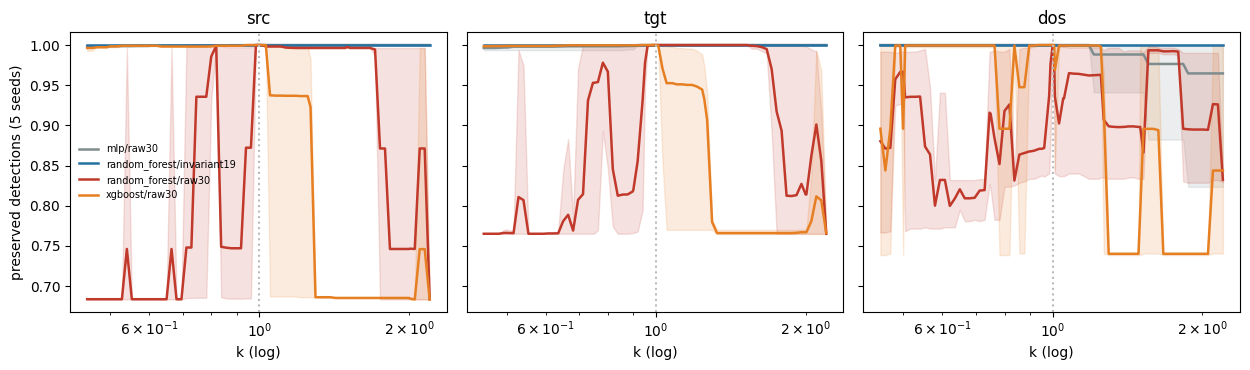

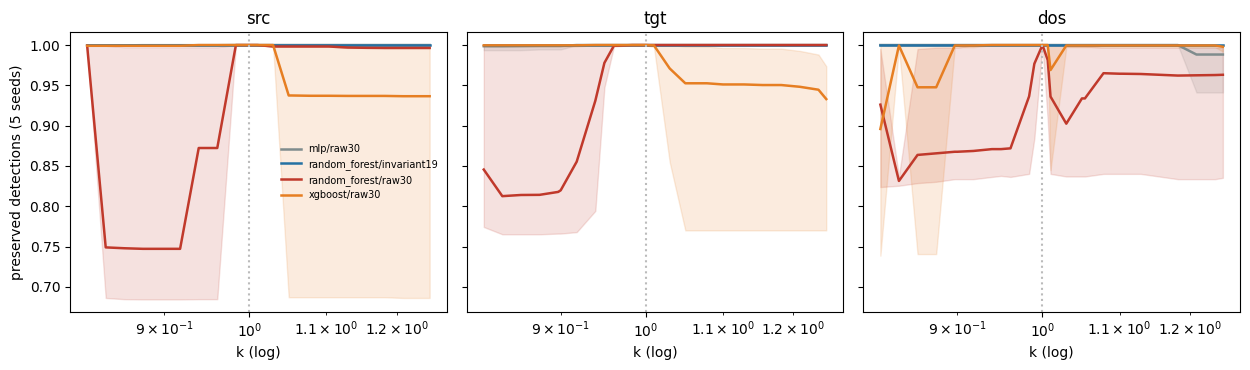

In [27]:
import traceback
try:
    KD = sorted(set(np.round(np.geomspace(0.45, 2.2, 70), 4).tolist()) | set(DISP_GRID))
    DENSE = []
    for kind, fset in (("random_forest", "raw30"), ("xgboost", "raw30"), ("mlp", "raw30"), ("random_forest", "invariant19")):
        for seed in RUN_SEEDS:
            sc = get_scorer(kind, fset, "none", seed); thr = src_thr(sc, fset)
            for dom in DOMS_RAW:
                d1 = sc(cprep(dom, "a", fset, 1.0)) >= thr
                for k in KD:
                    Xr, y = DOMS_RAW[dom]
                    dk = sc(prep(Xr[y == 1].reset_index(drop=True), fset, k)) >= thr
                    DENSE.append({"model": kind, "features": fset, "seed": seed, "domain": dom, "k": k,
                                  "preserved": (d1 & dk).sum() / max(d1.sum(), 1),
                                  "yield": dk.sum() / max(d1.sum(), 1)})
    DENSE = pd.DataFrame(DENSE)
    DENSE.to_csv(os.path.join(TAB, "R7_dense_grid.csv"), index=False)
    _cols = {"random_forest/raw30": "#c0392b", "xgboost/raw30": "#e67e22", "mlp/raw30": "#7f8c8d", "random_forest/invariant19": "#2471a3"}
    _doms = list(DOMS_RAW)
    for tag, xl in (("full", (0.45, 2.2)), ("zoom", (0.8, 1.25))):
        fig, axs = plt.subplots(1, len(_doms), figsize=(4.2 * len(_doms), 3.8), sharey=True)
        for ax, dom in zip(np.atleast_1d(axs), _doms):
            sub = DENSE[(DENSE.domain == dom) & (DENSE.k >= xl[0]) & (DENSE.k <= xl[1])]
            for (m, f), g in sub.groupby(["model", "features"]):
                st = g.groupby("k")["preserved"].agg(["mean", "min", "max"])
                c = _cols["{}/{}".format(m, f)]
                ax.plot(st.index, st["mean"], color=c, lw=1.8, label="{}/{}".format(m, f))
                ax.fill_between(st.index, st["min"], st["max"], color=c, alpha=0.15)
            ax.set_xscale("log"); ax.set_title(dom); ax.set_xlabel("k (log)"); ax.axvline(1, color="#bbb", ls=":")
        np.atleast_1d(axs)[0].set_ylabel("preserved detections (5 seeds)")
        np.atleast_1d(axs)[0].legend(fontsize=7, frameon=False)
        fig.tight_layout(); fig.savefig(os.path.join(FIG, "R7_dense_{}.png".format(tag)), dpi=300)
    print(DENSE.groupby(["model", "features", "domain"])["preserved"].min().round(3).to_string())
except Exception:
    print('!! R7 FAILED - continuing with next cell')
    traceback.print_exc()


### R8a — M10 - counterfactual single-field/group interventions, tree-path divergence, DoS2017 own-domain

In [28]:
import traceback
try:
    S30 = SPLIT["raw30"]
    with open(os.path.join(CKPT, "random_forest_raw30_s{}.pkl".format(RUN_SEEDS[0])), "rb") as fh:
        RF = pickle.load(fh)
    RT = calibrate_threshold_at_fpr(y_val, RF.predict_proba(S30["X_val"])[:, 1], TARGET_FPR, warn=False)
    XA = Xr_eval_src[y_eval_src == 1].reset_index(drop=True)
    det = lambda X_: RF.predict_proba(apply_scaler(S30["scaler"], build_raw(X_)[0]))[:, 1] >= RT
    D1 = det(XA)
    CF = []
    GROUPS = {"duration": ["duration"],
              "IAT min (flow/fwd/bwd)": ["flow_iat_min", "fwd_iat_min", "bwd_iat_min"],
              "IAT max": ["flow_iat_max", "fwd_iat_max", "bwd_iat_max"],
              "IAT mean": ["flow_iat_mean", "fwd_iat_mean", "bwd_iat_mean"],
              "IAT std": ["flow_iat_std", "fwd_iat_std", "bwd_iat_std"],
              "IAT totals": ["fwd_iat_tot", "bwd_iat_tot"],
              "active/idle": ["active_mean", "active_std", "idle_mean", "idle_std"],
              "rates (divided by k)": ["flow_byts_s", "flow_pkts_s"]}
    for k in (0.5, 0.9, 2.0):
        full = det(retime(XA, k))
        CLk = D1 & ~full
        for c in TIME_COLS + ["flow_byts_s", "flow_pkts_s"]:
            X_ = XA.copy(); X_[c] = X_[c] * (k if c in TIME_COLS else 1.0 / k)
            dk = det(X_)
            CF.append({"k": k, "intervention": "single: " + c, "lost_total": int((D1 & ~dk).sum()),
                       "lost_in_cluster": int((CLk & ~dk).sum()), "cluster_size": int(CLk.sum())})
        for gname, cols in GROUPS.items():
            X_ = XA.copy()
            for c in cols:
                X_[c] = X_[c] * (k if c in TIME_COLS else 1.0 / k)
            dk = det(X_)
            CF.append({"k": k, "intervention": "group: " + gname, "lost_total": int((D1 & ~dk).sum()),
                       "lost_in_cluster": int((CLk & ~dk).sum()), "cluster_size": int(CLk.sum())})
        CF.append({"k": k, "intervention": "full re-timing", "lost_total": int(CLk.sum()),
                   "lost_in_cluster": int(CLk.sum()), "cluster_size": int(CLk.sum())})
    CF = pd.DataFrame(CF)
    CF.to_csv(os.path.join(TAB, "R8_counterfactual_interventions.csv"), index=False)
    print(CF.sort_values(["k", "lost_in_cluster"], ascending=[True, False]).groupby("k").head(10).to_string(index=False))

    # tree-path divergence for cluster flows at k = 0.5
    CL5 = np.flatnonzero(D1 & ~det(retime(XA, 0.5)))
    if len(CL5) == 0:
        print('no cluster flows lost at k = 0.5; tree-path analysis skipped')
    else:
        Z0 = apply_scaler(S30["scaler"], build_raw(XA.iloc[CL5])[0])
        Z1 = apply_scaler(S30["scaler"], build_raw(retime(XA.iloc[CL5].reset_index(drop=True), 0.5))[0])
        div = Counter(); flipped_trees = []
        for ti, est in enumerate(RF.estimators_):
            t = est.tree_
            p0 = est.predict_proba(Z0)[:, 1]; p1 = est.predict_proba(Z1)[:, 1]
            flip = np.flatnonzero((p0 > 0.5) & (p1 <= 0.5))
            flipped_trees.append(len(flip) / max(len(CL5), 1))
            if len(flip) == 0:
                continue
            P0 = est.decision_path(Z0[flip]); P1 = est.decision_path(Z1[flip])
            for r in range(len(flip)):
                n0 = P0.indices[P0.indptr[r]:P0.indptr[r + 1]]; n1 = P1.indices[P1.indptr[r]:P1.indptr[r + 1]]
                common = 0
                for a_, b_ in zip(n0, n1):
                    if a_ != b_:
                        break
                    common = a_
                div[RAW_NAMES[t.feature[common]]] += 1
        print("mean fraction of trees whose vote flips for a cluster flow: {:.3f}".format(np.mean(flipped_trees)))
        print("split feature at the node where original and re-timed paths diverge:", div.most_common(10))
        # representative path: tree with most flips, first cluster flow
        _ti = int(np.argmax(flipped_trees)); est = RF.estimators_[_ti]; t = est.tree_
        n0 = est.decision_path(Z0[:1]).indices; n1 = est.decision_path(Z1[:1]).indices
        print("representative tree #{} (flow {}): node, feature, raw threshold, original value, re-timed value".format(_ti, CL5[0]))
        _s1 = set(n1.tolist())
        for i, node in enumerate(n0):
            if t.feature[node] < 0:
                v = t.value[node][0]
                print("   leaf {} p(attack)={:.3f}".format(node, v[1] / v.sum())); break
            f = t.feature[node]; nm = RAW_NAMES[f]
            raw_thr = float(np.expm1(t.threshold[node] * S30["scaler"]["scale"][f] + S30["scaler"]["mean"][f]))
            v0 = float(XA.iloc[CL5[0]][nm]); v1 = float(retime(XA.iloc[[CL5[0]]], 0.5).iloc[0][nm])
            mark = "  <-- re-timed flow goes the other way" if (i + 1 < len(n0) and n0[i + 1] not in _s1) else ""
            print("   node {:4d} {:<14} thr {:>14.1f} | orig {:>14.1f} | retimed {:>14.1f}{}".format(node, nm, raw_thr, v0, v1, mark))
        _v = t.value[n1[-1]][0]
        print("re-timed path ends at leaf p(attack)={:.3f}".format(_v[1] / _v.sum()))
except Exception:
    print('!! R8a FAILED - continuing with next cell')
    traceback.print_exc()


  k          intervention  lost_total  lost_in_cluster  cluster_size
0.5        full re-timing         351              351           351
0.5      single: duration           0                0           351
0.5 single: flow_iat_mean           0                0           351
0.5  single: flow_iat_std           0                0           351
0.5  single: flow_iat_max           0                0           351
0.5  single: flow_iat_min           0                0           351
0.5   single: fwd_iat_tot           0                0           351
0.5  single: fwd_iat_mean           0                0           351
0.5   single: fwd_iat_std           0                0           351
0.5   single: fwd_iat_max           0                0           351
0.9        full re-timing         350              350           350
0.9      single: duration           0                0           350
0.9 single: flow_iat_mean           0                0           350
0.9  single: flow_iat_std         

### R8b — M10 - robustness on CIC-DoS2017: train there, re-time its own flows

In [29]:
import traceback
try:
    if HAS_DOS:
        poolD = np.flatnonzero(np.isin(famD_all, ("benign", "slowloris")))
        rr = np.random.default_rng(SPLIT_SEED + 9).permutation(poolD)
        n1, n2 = int(0.6 * len(rr)), int(0.8 * len(rr))
        trD, vaD, teD = rr[:n1], rr[n1:n2], rr[n2:]
        yDall = (famD_all == "slowloris").astype(np.int64)
        print("DoS2017 own split: train {:,} ({:,} slowloris) | val {:,} | test {:,} ({:,} slowloris)".format(
            len(trD), int(yDall[trD].sum()), len(vaD), len(teD), int(yDall[teD].sum())))
        OWN = []
        for base in ("raw30", "invariant19"):
            fn = FEATURE_SETS[base][0]
            MD, _ = fn(XrD_all); sclD = fit_scaler(MD[trD])
            Ztr, Zva, Zev = apply_scaler(sclD, MD[trD]), apply_scaler(sclD, MD[vaD]), apply_scaler(sclD, MD[teD])
            XaD = XrD_all.iloc[teD[yDall[teD] == 1]].reset_index(drop=True)
            for kind in ("random_forest", "xgboost", "mlp"):
                for seed in (1, 2, 3):
                    set_seed(seed)
                    if kind == "random_forest":
                        clf = RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=-1).fit(Ztr, yDall[trD]); sc = lambda Z, _c=clf: _c.predict_proba(Z)[:, 1]
                    elif kind == "xgboost":
                        clf = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9,
                                            eval_metric="logloss", random_state=seed, n_jobs=-1).fit(Ztr, yDall[trD]); sc = lambda Z, _c=clf: _c.predict_proba(Z)[:, 1]
                    else:
                        mdl, _ = train_model(make_model("mlp", TrainConfig(), d_in=Ztr.shape[1]), Ztr, yDall[trD], Zva, yDall[vaD],
                                             TrainConfig(), verbose=False); sc = lambda Z, _m=mdl: predict_probs(_m, Z)
                    thr = calibrate_threshold_at_fpr(yDall[vaD], sc(Zva), TARGET_FPR, warn=False)
                    r = evaluate(sc, Zev, yDall[teD], thr)
                    d1 = sc(prep(XaD, base, 1.0, sclD)) >= thr
                    pres, gain = [], []
                    for k in DISP_GRID:
                        dk = sc(prep(XaD, base, k, sclD)) >= thr
                        pres.append((d1 & dk).sum() / max(d1.sum(), 1)); gain.append(int((~d1 & dk).sum()))
                    r.update({"model": kind, "features": base, "seed": seed, "gridmin_preserved": min(pres),
                              "argmin_k": DISP_GRID[int(np.argmin(pres))], "max_gained": max(gain)})
                    OWN.append(r)
        OWN = pd.DataFrame(OWN)
        OWN.to_csv(os.path.join(TAB, "R8_dos2017_own_domain_retention.csv"), index=False)
        print(OWN.groupby(["model", "features"])[["ap", "fnr_m", "gridmin_preserved", "max_gained"]].agg(["mean", "min"]).round(4).to_string())
except Exception:
    print('!! R8b FAILED - continuing with next cell')
    traceback.print_exc()


DoS2017 own split: train 112,134 (1,155 slowloris) | val 37,378 | test 37,378 (377 slowloris)
                               ap           fnr_m         gridmin_preserved         max_gained    
                             mean     min    mean     min              mean     min       mean min
model         features                                                                            
mlp           invariant19  0.8815  0.8785  0.2573  0.2334            0.9918  0.9782     0.6667   0
              raw30        0.9614  0.9600  0.0716  0.0663            0.7998  0.7717     6.3333   3
random_forest invariant19  0.9072  0.9070  0.2272  0.2255            1.0000  1.0000     0.0000   0
              raw30        0.9706  0.9686  0.0212  0.0212            0.7416  0.7317     2.0000   2
xgboost       invariant19  0.9051  0.9047  0.2255  0.2255            1.0000  1.0000     0.0000   0
              raw30        0.9865  0.9844  0.0230  0.0212            0.6151  0.4823     1.6667   1


### R10 — reverse direction 2018 → 2017, 5 seeds, flow-level preservation (~20 min)

In [30]:
import traceback
try:
    # ============================================================
    # CELL R10 : REVERSE transfer 2018 -> 2017 with 5 seeds and flow-level preservation
    #   Paste as the LAST code cell of paper2_revision (before the zip cell R9 is fine too).
    # ============================================================
    REV_SEEDS = [1, 2, 3, 4, 5]
    pool = np.setdiff1d(np.arange(len(y_tgt_all)), sel_t)
    rr = np.random.default_rng(SPLIT_SEED + 7).permutation(pool)
    n_tr2 = int(0.75 * len(rr)); r_tr, r_va = rr[:n_tr2], rr[n_tr2:]
    ytr2, yva2 = y_tgt_all[r_tr], y_tgt_all[r_va]
    atk17 = Xr_src_all.iloc[sel_s][y_eval_src == 1].reset_index(drop=True)
    atk18 = Xr_tgt_all.iloc[sel_t][y_eval_tgt == 1].reset_index(drop=True)
    rows, pres_rows = [], []
    for fset in ("raw30", "invariant19", "inv18"):
        base, cols = FSPEC[fset]
        fn = FEATURE_SETS[base][0]
        sel = (lambda Z: Z) if cols is None else (lambda Z, _c=cols: Z[:, _c])
        M18, _ = fn(Xr_tgt_all); M17, _ = fn(Xr_src_all)
        sc2 = fit_scaler(M18[r_tr])
        Xtr2, Xva2 = sel(apply_scaler(sc2, M18[r_tr])), sel(apply_scaler(sc2, M18[r_va]))
        Xe_in, Xe_out = sel(apply_scaler(sc2, M18[sel_t])), sel(apply_scaler(sc2, M17[sel_s]))
        kinds = ("mlp",) if fset == "inv18" else ("random_forest", "xgboost", "mlp")
        for kind in kinds:
            for seed in REV_SEEDS:
                set_seed(seed)
                if kind == "random_forest":
                    clf = RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=-1).fit(Xtr2, ytr2)
                    scr = lambda Z, _c=clf: _c.predict_proba(Z)[:, 1]
                elif kind == "xgboost":
                    clf = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9,
                                        eval_metric="logloss", random_state=seed, n_jobs=-1).fit(Xtr2, ytr2)
                    scr = lambda Z, _c=clf: _c.predict_proba(Z)[:, 1]
                else:
                    mdl, _ = train_model(make_model("mlp", TrainConfig(), d_in=Xtr2.shape[1]), Xtr2, ytr2, Xva2, yva2,
                                         TrainConfig(), verbose=False)
                    scr = lambda Z, _m=mdl: predict_probs(_m, Z)
                thr = calibrate_threshold_at_fpr(yva2, scr(Xva2), TARGET_FPR, warn=False)
                for dom, Xe, ye in (("2018 (in)", Xe_in, y_eval_tgt), ("2017 (out)", Xe_out, y_eval_src)):
                    s = scr(Xe); tm = calibrate_threshold_at_fpr(ye, s, TARGET_FPR, warn=False)
                    m, ms = compute_metrics(ye, s, tm, "full"), compute_metrics(ye, s, thr, "full")
                    rows.append({"model": kind, "features": fset, "seed": seed, "eval": dom, "ap": m["auc_pr"],
                                 "fnr_matched": m["fnr"], "fpr_srccal": ms["benign_fpr"], "fnr_srccal": ms["fnr"]})
                for dom, Xa in (("2018 (in)", atk18), ("2017 (out)", atk17)):
                    d1 = scr(sel(apply_scaler(sc2, fn(Xa)[0]))) >= thr
                    P, G, Lr = [], [], []
                    for k in DISP_GRID:
                        dk = scr(sel(apply_scaler(sc2, fn(retime(Xa, k))[0]))) >= thr
                        P.append((d1 & dk).sum() / max(d1.sum(), 1)); G.append(int((~d1 & dk).sum())); Lr.append(int((d1 & ~dk).sum()))
                    pres_rows.append({"model": kind, "features": fset, "seed": seed, "eval": dom, "det1": d1.mean(),
                                      "gridmin_preserved": min(P), "max_lost": max(Lr), "max_gained": max(G)})
                print("  done", kind, fset, seed)
    REV5 = pd.DataFrame(rows); REVP = pd.DataFrame(pres_rows)
    REV5.to_csv(os.path.join(TAB, "R10_reverse_5seeds.csv"), index=False)
    REVP.to_csv(os.path.join(TAB, "R10_reverse_preservation.csv"), index=False)
    print(REV5.groupby(["model", "features", "eval"])[["ap", "fnr_matched", "fpr_srccal", "fnr_srccal"]].agg(["mean", "std"]).round(4).to_string())
    print(REVP.groupby(["model", "features", "eval"])[["det1", "gridmin_preserved", "max_lost", "max_gained"]].agg(["mean", "min", "max"]).round(3).to_string())
except Exception:
    print('!! R10 FAILED - continuing'); traceback.print_exc()


  done random_forest raw30 1
  done random_forest raw30 2
  done random_forest raw30 3
  done random_forest raw30 4
  done random_forest raw30 5
  done xgboost raw30 1
  done xgboost raw30 2
  done xgboost raw30 3
  done xgboost raw30 4
  done xgboost raw30 5
  done mlp raw30 1
  done mlp raw30 2
  done mlp raw30 3
  done mlp raw30 4
  done mlp raw30 5
  done random_forest invariant19 1
  done random_forest invariant19 2
  done random_forest invariant19 3
  done random_forest invariant19 4
  done random_forest invariant19 5
  done xgboost invariant19 1
  done xgboost invariant19 2
  done xgboost invariant19 3
  done xgboost invariant19 4
  done xgboost invariant19 5
  done mlp invariant19 1
  done mlp invariant19 2
  done mlp invariant19 3
  done mlp invariant19 4
  done mlp invariant19 5
  done mlp inv18 1
  done mlp inv18 2
  done mlp inv18 3
  done mlp inv18 4
  done mlp inv18 5
                                          ap         fnr_matched         fpr_srccal         fnr_srccal   

### R11 — benign re-timing across pacing factors and thresholds (~10 min)

In [31]:
import traceback
try:
    # ============================================================
    # CELL R11 : benign-flow re-timing across pacing factors AND operating thresholds
    #   thresholds: source-calibrated at 0.01%, 0.1%, 1% FPR (deployable) and
    #               matched 0.1% FPR fitted on the domain's benign flows at k = 1 (oracle), all frozen.
    # ============================================================
    TAUS = (0.0001, 0.001, 0.01)
    BEN = []
    _ben_arms = [(k, f, a) for k, f, a in ALL_ARMS] + [("mlp", "inv18", "none"), ("mlp", "raw29", "none")]
    for kind, fset, aug in _ben_arms:
        for seed in RUN_SEEDS:
            sc = get_scorer(kind, fset, aug, seed)
            sval = sc(ev_mats(fset, "X_val"))
            thr = {"src_cal_{:g}".format(t): calibrate_threshold_at_fpr(y_val, sval, t, warn=False) for t in TAUS}
            for dom in [d for d in ("src", "tgt", "dos") if d in DOMS_RAW]:
                s1 = sc(cprep(dom, "b", fset, 1.0))
                thr_m = calibrate_threshold_at_fpr(np.zeros(len(s1), dtype=int), s1, TARGET_FPR, warn=False)
                ths = dict(thr, matched_0_001=thr_m)
                for k in DISP_GRID:
                    sk = s1 if k == 1.0 else sc(cprep(dom, "b", fset, k))
                    for tname, t in ths.items():
                        f1 = float((s1 >= t).mean()); fk = float((sk >= t).mean())
                        BEN.append({"model": kind, "features": fset, "aug": aug, "seed": seed, "domain": dom,
                                    "threshold": tname, "k": k, "n_benign": len(s1), "fpr_1": f1, "fpr_k": fk,
                                    "fp_1": int((s1 >= t).sum()), "fp_k": int((sk >= t).sum()),
                                    "new_fp": int(((sk >= t) & ~(s1 >= t)).sum())})
        print("  benign re-timing done:", kind, fset, aug)
    BEN = pd.DataFrame(BEN)
    BEN.to_csv(os.path.join(TAB, "R11_benign_retiming.csv"), index=False)
    _g = BEN.assign(ratio=BEN.fpr_k / BEN.fpr_1.replace(0, np.nan))
    _sum = _g.groupby(["model", "features", "aug", "domain", "threshold"]).agg(
        fpr_1=("fpr_1", "mean"), fpr_k_max=("fpr_k", "max"), max_ratio=("ratio", "max"), max_new_fp=("new_fp", "max"))
    _le1 = _g[_g.k <= 1.0].groupby(["model", "features", "aug", "domain", "threshold"])["ratio"].max().rename("max_ratio_k_le_1")
    _sum = _sum.join(_le1)
    _sum.to_csv(os.path.join(TAB, "R11_benign_retiming_summary.csv"))
    print(_sum.round(4).to_string())
except Exception:
    print('!! R11 FAILED - continuing'); traceback.print_exc()


  benign re-timing done: fgsan invariant19 retime
  benign re-timing done: fgsan invariant19 none
  benign re-timing done: fgsan_noattn invariant19 none
  benign re-timing done: mlp invariant19 none
  benign re-timing done: mlp raw30 none
  benign re-timing done: random_forest invariant19 none
  benign re-timing done: random_forest raw30 none
  benign re-timing done: xgboost invariant19 none
  benign re-timing done: xgboost raw30 none
  benign re-timing done: mlp inv18 none
  benign re-timing done: mlp raw29 none
                                                         fpr_1  fpr_k_max  max_ratio  max_new_fp  max_ratio_k_le_1
model         features    aug    domain threshold                                                                 
fgsan         invariant19 none   dos    matched_0_001   0.0010     0.0082     8.2381         152            1.0000
                                        src_cal_0.0001  0.0097     0.0555     3.2500         246            2.3333
                     

### R9 — zip all tables and figures for download

In [32]:
import traceback
try:
    import zipfile
    _zip = os.path.join(WORK, "paper2_revision_outputs.zip")
    with zipfile.ZipFile(_zip, "w", zipfile.ZIP_DEFLATED) as z:
        for sub in ("tables", "figures", "logs"):
            for root, _, files in os.walk(os.path.join(PROJ, sub)):
                for f in files:
                    full = os.path.join(root, f)
                    z.write(full, os.path.relpath(full, PROJ))
        for f in ("results.csv", "Ledger.md"):
            if os.path.exists(os.path.join(PROJ, f)):
                z.write(os.path.join(PROJ, f), f)
    print("download:", _zip, "({:.1f} MB)".format(os.path.getsize(_zip) / 1e6))
except Exception:
    print('!! R9 FAILED - continuing with next cell')
    traceback.print_exc()


download: /kaggle/working/paper2_revision_outputs.zip (0.9 MB)
